# 03 · K-Means: establecer la segmentación de referencia

Mercedes-Benz Customer Clustering — Malackathon 2026

**Objetivo:** elegir k contrastando geometría, tamaños e inicialización e identificar clientes próximos a fronteras.


## Continuidad del estudio

Esta entrega establece la segmentación de referencia. Se comparan cuatro poblaciones independientes, sin concatenarlas. Las entregas siguientes desarrollan interpretación, comparación, PCA y robustez sobre sus resultados.

El paquete **segmentacion_ml.zip**, generado por 03 y ampliado en las siguientes entregas, contiene resultados numéricos, sin código ejecutable ni la matriz de features. Al cambiar de sesión de Colab se sube junto a los CSV. Los únicos archivos de código entregados son estos notebooks.


## Configuración

Ejecutar en orden. En Colab, usar `DATA_MODE="real_upload"`. Se excluye la clave técnica `Unnamed: 0`. La entrega 03 audita las escalas y define explícitamente una representación de varianza unitaria por variable. Las siguientes reutilizan sus parámetros, sin ajustarlos otra vez. Los CSV permanecen intactos. Cada etiqueta de cluster es local a su población.


In [37]:
from pathlib import Path
from io import BytesIO
import json, sys, importlib.util
from time import perf_counter
import uuid
STARTED = perf_counter()

# Interfaz v3: matrices de modelado y metadatos separados; resultados secuenciales.
DATA_MODE = "real"  # En Colab: "real_upload" y seleccionar los CSV y el paquete de la entrega anterior.
SEGMENT_ID = "AT_B2B"
RUN_ALL_SEGMENTS = True
SEGMENT_FILES = {name: f"{name}_features_scaled.csv" for name in ("AT_B2B", "AT_B2C", "CH_B2B", "CH_B2C")}
METADATA_FILES = {name: f"{name}_metadata.csv" for name in SEGMENT_FILES}
ID_COLUMN = "Unnamed: 0"  # Clave técnica de la exportación; nunca es una feature.
CSV_OPTIONS = dict(sep=",", decimal=".", encoding="utf-8-sig")
SCALING_POLICY = "standardize"  # Decisión explícita común: media 0 y varianza 1 por variable.
REFERENCE_FILE = "segmentacion_ml.zip"
INSTALL_MISSING = False
SEED = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = 2000
FEATURE_DESCRIPTIONS = {'age_range_encoded': 'Rango de edad codificado', 'vehicle_age_years': 'Antigüedad del vehículo', 'estimated_itv_passes': 'Inspecciones técnicas estimadas', 'is_current_vehicle': 'Vehículo actual', 'months_as_mb_customer': 'Antigüedad de la relación', 'currently_connected_vehicles': 'Vehículos conectados', 'workshop_frequency_yearly': 'Frecuencia anual de taller', 'workshop_visits_warranty_goodwill': 'Visitas en garantía o atención comercial', 'marketing_receptivity_score': 'Receptividad a marketing', 'purchasing_power_per_inhabitant_eur': 'Poder adquisitivo por habitante del área', 'population': 'Población del área', 'has_telemetry_active': 'Telemetría activa', 'trip_distance_median': 'Mediana de distancia por trayecto', 'speed_median': 'Mediana de velocidad', 'fuel_consumption_average': 'Consumo medio', 'operating_hours_total': 'Horas totales de funcionamiento'}
K_VALUES = list(range(2,9))
SEED_REPEATS = 3
INDIVIDUAL_REFERENCE_SIZE = 2000
HYPERPARAMETER_MAX_SAMPLES = 20000
BOUNDARY_THRESHOLD = .15
OUTPUT_DIR = Path("outputs") / "03" / uuid.uuid4().hex[:8]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
required = {"numpy":"numpy>=1.26,<3", "pandas":"pandas>=2.1,<3", "sklearn":"scikit-learn>=1.3,<2",
            "scipy":"scipy>=1.11,<2", "matplotlib":"matplotlib>=3.8,<4", "threadpoolctl":"threadpoolctl>=3.2,<4"}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING:
        raise ImportError("Instalar las dependencias ausentes o activar INSTALL_MISSING: " + repr(missing))
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install",*missing])
try:
    display
except NameError:
    from IPython.display import display


## Funciones del estudio

Las celdas plegadas agrupan validación, algoritmos y presentación. El desarrollo del análisis aparece después en celdas breves, cada una con su pregunta y su resultado.


In [38]:
from __future__ import annotations
"""Contrato de features procesadas y trazabilidad posicional por cliente."""


from dataclasses import dataclass
from numbers import Integral
from pathlib import Path
from typing import Iterable, Optional, Union

import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_complex_dtype, is_numeric_dtype, is_scalar


@dataclass(frozen=True)
class FeatureData:
    """Resultado validado: X[i] corresponde exactamente a client_ids.iloc[i].

    Crear mediante validate_features/load_features. X es una copia float64 de
    solo lectura; el índice original del DataFrame no se utiliza como identidad.
    Los identificadores se conservan con su tipo, sin ordenar ni convertirlos.
    """

    X: np.ndarray
    client_ids: pd.Series
    feature_names: tuple[str, ...]
    constant_features: tuple[str, ...]

    @property
    def n_samples(self) -> int:
        return self.X.shape[0]

    @property
    def n_features(self) -> int:
        return self.X.shape[1]

    def assignments(self, labels: Iterable[int]) -> pd.DataFrame:
        """Adjuntar etiquetas por posición, sin alinear índices de pandas.

        Admite etiquetas enteras (también -1 para futuras extensiones).
        Una Series debe estar ya en el orden de X; no se interpreta su índice.
        """
        values = np.asarray(list(labels))
        if values.ndim != 1 or len(values) != self.n_samples:
            raise ValueError("Debe existir una etiqueta por fila de X, en el mismo orden.")
        if values.dtype.kind not in "iu":
            raise ValueError("Las etiquetas de cluster deben ser enteros, sin nulos.")
        result = self.client_ids.reset_index(drop=True).to_frame(name="client_id").copy()
        result["cluster"] = values.copy()
        return result


def _positive_integer(value: int, name: str, minimum: int = 1) -> int:
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, Integral) or value < minimum:
        raise ValueError(f"{name} debe ser un entero >= {minimum}.")
    return int(value)


def validate_k_values(
    k_values: Iterable[int],
    n_samples: int,
    *,
    n_distinct_rows: Optional[int] = None,
) -> tuple[int, ...]:
    """Validar candidatos para clustering evaluado mediante Silhouette.

    Se exige 2 <= k < n_samples. Si se conoce la cantidad de filas distintas,
    k no puede superarla. No se modifica, ordena ni recorta la lista solicitada.
    No entrena modelos ni selecciona k. k=1 (solo codo) queda fuera del contrato
    de evaluación conjunta y podrá tratarse aparte en Fase 2.
    """
    n_samples = _positive_integer(n_samples, "n_samples", minimum=3)
    if n_distinct_rows is not None:
        n_distinct_rows = _positive_integer(n_distinct_rows, "n_distinct_rows")
        if n_distinct_rows > n_samples:
            raise ValueError("n_distinct_rows no puede superar n_samples.")
    try:
        candidates = tuple(k_values)
    except TypeError as exc:
        raise ValueError("k_values debe ser una secuencia no vacía de enteros.") from exc
    if not candidates:
        raise ValueError("k_values no puede estar vacío.")
    checked = tuple(_positive_integer(k, "k", minimum=2) for k in candidates)
    if len(set(checked)) != len(checked):
        raise ValueError("k_values contiene candidatos duplicados.")
    if any(k >= n_samples for k in checked):
        raise ValueError("Cada k debe ser menor que n_samples para evaluar Silhouette.")
    if n_distinct_rows is not None and any(k > n_distinct_rows for k in checked):
        raise ValueError("k no puede superar el número de filas de features distintas.")
    return checked


def validate_features(
    frame: pd.DataFrame,
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
) -> FeatureData:
    """Validar una matriz de features sin preprocesarla.

    Acepta features reales numéricas y booleanas ya codificadas, incluidas
    extensiones numéricas nullable si no contienen nulos. Rechaza strings
    numéricos, categorías, fechas y complejos. Las columnas constantes se
    reportan y conservan; falla si ninguna feature varía.

    Complejidad O(n*p), salvo la comprobación opcional de filas únicas para k
    (ordenación, sin matrices de distancias entre clientes).
    """
    if not isinstance(frame, pd.DataFrame):
        raise TypeError("La entrada debe ser un pandas.DataFrame.")
    min_samples = _positive_integer(min_samples, "min_samples", minimum=3)
    if frame.columns.has_duplicates:
        raise ValueError("Los nombres de columnas deben ser únicos.")
    if not all(isinstance(name, str) and name.strip() for name in frame.columns):
        raise ValueError("Los nombres de columnas deben ser strings no vacíos.")
    if "client_id" not in frame.columns:
        raise ValueError("Falta la columna obligatoria client_id.")
    if len(frame) < min_samples:
        raise ValueError(f"Número insuficiente de muestras: se necesitan al menos {min_samples}.")

    ids = frame["client_id"]
    if ids.isna().any():
        raise ValueError("client_id no puede contener nulos.")
    for value in ids:
        if not is_scalar(value):
            raise ValueError("client_id debe contener identificadores escalares y hashables.")
        try:
            hash(value)
        except TypeError as exc:
            raise ValueError("client_id debe contener identificadores hashables.") from exc
        if isinstance(value, str) and not value.strip():
            raise ValueError("client_id no puede contener strings vacíos.")
        if isinstance(value, (float, np.floating)) and not np.isfinite(value):
            raise ValueError("client_id no puede contener identificadores infinitos.")
    if ids.duplicated().any():
        raise ValueError("client_id contiene identificadores duplicados.")

    names = tuple(name for name in frame.columns if name != "client_id")
    if not names:
        raise ValueError("La matriz no contiene features.")
    features = frame.loc[:, list(names)]
    incompatible = [
        name for name, dtype in features.dtypes.items()
        if not (is_numeric_dtype(dtype) or is_bool_dtype(dtype)) or is_complex_dtype(dtype)
    ]
    if incompatible:
        raise ValueError(f"Features con tipos no numéricos reales: {incompatible}.")
    if features.isna().to_numpy().any():
        raise ValueError("Las features contienen NaN o valores nulos.")
    try:
        X = features.to_numpy(dtype=np.float64, na_value=np.nan, copy=True)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError("Las features no pueden representarse como matriz float64.") from exc
    if not np.isfinite(X).all():
        raise ValueError("Las features contienen NaN o valores infinitos.")
    varying = np.any(X != X[0], axis=0)
    if not varying.any():
        raise ValueError("Matriz sin características útiles: todas las features son constantes.")
    if k_values is not None:
        validate_k_values(k_values, len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    X = np.ascontiguousarray(X)
    X.setflags(write=False)
    return FeatureData(
        X=X,
        client_ids=ids.reset_index(drop=True).copy(deep=True),
        feature_names=names,
        constant_features=tuple(name for name, varies in zip(names, varying) if not varies),
    )


def load_features(
    source: Union[pd.DataFrame, str, Path] = "segment_01.csv",
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
    csv_options: Optional[dict] = None,
) -> FeatureData:
    """Misma interfaz para DataFrame, CSV o Parquet de un segmento.

    Las rutas relativas se resuelven desde el directorio de ejecución.
    Leer Parquet requiere pyarrow; el índice guardado en el archivo no es un ID.
    """
    if isinstance(source, pd.DataFrame):
        frame = source
    elif isinstance(source, (str, Path)):
        path = Path(source)
        if path.suffix.lower() not in {".csv", ".parquet"}:
            raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
        if not path.is_file():
            raise FileNotFoundError(f"No existe el archivo solicitado: {path}")
        try:
            frame = read_processed_table(path, csv_options=csv_options)
        except ImportError as exc:
            raise ImportError("La lectura Parquet requiere instalar pyarrow.") from exc
    else:
        raise TypeError("source debe ser un DataFrame o la ruta de un CSV/Parquet.")
    return validate_features(frame, min_samples=min_samples, k_values=k_values)


def read_processed_table(source, *, filename=None, csv_options=None, id_column="client_id"):
    """Lectura de una tabla ya procesada, sin preprocesamiento adicional.

    filename identifica el formato cuando source es un buffer de subida. Los IDs
    de CSV se conservan como texto; no se infiere su significado numérico.
    """
    suffix = str(filename if filename is not None else source).replace("\\", "/").rsplit(".", 1)[-1].lower()
    if suffix == "parquet":
        return pd.read_parquet(source, engine="pyarrow")
    if suffix != "csv":
        raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
    options = {"sep": ",", "decimal": ".", "encoding": "utf-8-sig"}
    if csv_options:
        if set(csv_options)-set(options):
            raise ValueError("CSV_OPTIONS solo admite sep, decimal y encoding.")
        options.update(csv_options)
    return pd.read_csv(source, converters={id_column: str}, low_memory=False, **options)


In [39]:
from __future__ import annotations
"""Evaluación geométrica: muestra común y Silhouette individual por bloques."""


import numpy as np
import pandas as pd
from sklearn import config_context
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
    normalized_mutual_info_score, pairwise_distances_chunked, silhouette_samples,
)


def evaluation_indices(n_samples, sample_size=2000, random_state=42):
    """Muestreo uniforme sin reemplazo, independiente de las etiquetas."""
    if n_samples < 3 or not isinstance(sample_size, (int, np.integer)) or sample_size < 3:
        raise ValueError("Se necesitan n_samples y sample_size >= 3.")
    return np.sort(np.random.default_rng(random_state).choice(
        n_samples, min(n_samples, sample_size), replace=False,
    ))


def partition_scores(X, labels, *, indices=None, sample_size=2000, random_state=42):
    """DB/CH/WCSS en X completa; Silhouette en una muestra común controlada.

    WCSS se calcula respecto a las medias empíricas de la partición para poder
    comparar asignaciones de distintos algoritmos. Solo coincide con la inercia
    de K-Means cuando sus centros son esas medias. No usa etiquetas verdaderas.
    """
    labels = np.asarray(labels)
    if labels.ndim != 1 or len(labels) != len(X):
        raise ValueError("Las etiquetas deben corresponder a las filas de X.")
    if indices is None:
        indices = evaluation_indices(len(X), sample_size, random_state)
    indices = np.asarray(indices, dtype=int)
    if len(indices) < 3 or len(np.unique(indices)) != len(indices) or np.any(indices < 0) or np.any(indices >= len(X)):
        raise ValueError("Índices de evaluación inválidos.")
    unique, counts = np.unique(labels, return_counts=True)
    means = np.array([X[labels == c].mean(axis=0) for c in unique])
    wcss = sum(float(np.sum((X[labels == c] - mean) ** 2)) for c, mean in zip(unique, means))
    result = dict(
        n_clusters=len(unique), min_cluster_size=int(counts.min()),
        min_cluster_fraction=float(counts.min() / len(X)), max_cluster_fraction=float(counts.max() / len(X)),
        within_ss=wcss, silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan,
        silhouette_n=len(indices), silhouette_estimated=len(indices) < len(X),
        silhouette_clusters_seen=len(np.unique(labels[indices])), status="ok",
    )
    if not 2 <= len(unique) < len(X):
        result["status"] = "invalid_partition"
        return result
    result["davies_bouldin"] = float(davies_bouldin_score(X, labels))
    result["calinski_harabasz"] = float(calinski_harabasz_score(X, labels))
    sub_labels = labels[indices]
    if 2 <= len(np.unique(sub_labels)) < len(indices):
        # sklearn utiliza distancias por bloques; nunca guardamos una matriz n*n.
        with config_context(working_memory=32):
            scores = silhouette_samples(X[indices], sub_labels, metric="euclidean")
        result["silhouette"] = float(scores.mean())
    else:
        result["status"] = "silhouette_undefined_in_sample"
    return result


def individual_silhouette(X, labels, *, reference_size=2000, random_state=42, working_memory=32):
    """Silhouette y vecino por cliente, sin conservar distancias cuadráticas.

    Si n<=reference_size es exacto. En datasets grandes, cada cliente se compara
    con anclas uniformes comunes: estima distancias medias por grupo, O(n*m*p),
    memoria por bloque. Esta estimación individual NO es el score global de una
    submuestra. Una clase sin anclas produce NaN en lugar de falsa certeza.
    Los singletons reales reciben 0 como en sklearn; no son evidencia de calidad.
    """
    labels = np.asarray(labels)
    if labels.shape != (len(X),) or not 2 <= len(np.unique(labels)) < len(X):
        raise ValueError("Silhouette requiere entre 2 y n-1 grupos y etiquetas por fila.")
    refs = evaluation_indices(len(X), reference_size, random_state)
    clusters, encoded = np.unique(labels, return_inverse=True)
    counts = np.bincount(encoded, minlength=len(clusters))
    ref_groups = encoded[refs]
    ref_counts = np.bincount(ref_groups, minlength=len(clusters))
    missing_clusters = int(np.sum(ref_counts == 0))
    anchor_position = np.full(len(X), -1, dtype=int)
    anchor_position[refs] = np.arange(len(refs))
    values = np.full(len(X), np.nan)
    neighbor = np.full(len(X), np.nan)
    a_all, b_all = np.full(len(X), np.nan), np.full(len(X), np.nan)
    start = 0
    for distances in pairwise_distances_chunked(X, X[refs], metric="euclidean", working_memory=working_memory):
        stop = start + len(distances)
        own = encoded[start:stop]
        position = anchor_position[start:stop]
        rows = np.arange(len(distances))
        present = position >= 0
        distances[rows[present], position[present]] = 0.0
        mean_distance = np.column_stack([
            distances[:, ref_groups == c].sum(axis=1) / ref_counts[c]
            if ref_counts[c] else np.full(len(distances), np.nan)
            for c in range(len(clusters))
        ])
        divisor = ref_counts[own] - present.astype(int)
        own_sum = np.array([distances[i, ref_groups == c].sum() for i, c in enumerate(own)])
        a = np.divide(own_sum, divisor, out=np.full(len(rows), np.nan), where=divisor > 0)
        mean_distance[rows, own] = np.inf
        mean_distance = np.where(np.isnan(mean_distance), np.inf, mean_distance)
        best = np.argmin(mean_distance, axis=1)
        b = mean_distance[rows, best]
        # Si falta un rival no sabemos si sería el grupo medio más cercano.
        valid = np.isfinite(a) & np.isfinite(b) & (missing_clusters == 0)
        scale = np.maximum(a[valid], b[valid])
        local = np.full(len(rows), np.nan)
        local[valid] = np.divide(b[valid] - a[valid], scale, out=np.zeros(valid.sum()), where=scale > 0)
        local[counts[own] == 1] = 0.0
        values[start:stop] = local
        neighbor[start:stop] = np.where(np.isfinite(b) & (missing_clusters == 0), clusters[best], np.nan)
        a_all[start:stop], b_all[start:stop] = a, np.where(np.isfinite(b) & (missing_clusters == 0), b, np.nan)
        start = stop
    return pd.DataFrame(dict(
        silhouette=values, silhouette_neighbor=neighbor, mean_own_distance=a_all,
        mean_neighbor_distance=b_all, silhouette_estimated=len(refs) < len(X),
        silhouette_reference_n=len(refs),
        silhouette_missing_anchor_clusters=missing_clusters,
    ))


def partition_geometry(X, labels):
    """Dispersión y separación entre centroides; no supone intersecciones reales."""
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    rows, centers = [], {}
    for c in clusters:
        points = X[labels == c]
        center = points.mean(axis=0)
        distances = np.linalg.norm(points - center, axis=1)
        centers[c] = center
        rows.append(dict(cluster=int(c), n_clients=len(points), fraction=len(points) / len(X),
                         mean_radius=distances.mean(), rms_radius=np.sqrt(np.mean(distances**2)),
                         radius_q95=np.quantile(distances, .95)))
    summary = pd.DataFrame(rows).set_index("cluster", drop=False)
    pairs = []
    for i, a in enumerate(clusters):
        for b in clusters[i+1:]:
            distance = float(np.linalg.norm(centers[a] - centers[b]))
            scatter = float(summary.loc[a, "mean_radius"] + summary.loc[b, "mean_radius"])
            pairs.append(dict(cluster_a=int(a), cluster_b=int(b), centroid_distance=distance,
                              scatter_over_separation=scatter / distance if distance > 0 else np.inf))
    return summary.reset_index(drop=True), pd.DataFrame(pairs)


def agreement_matrices(assignments):
    """ARI y NMI invariantes a permutaciones; cada vector usa los mismos clientes."""
    names = list(assignments)
    ari = pd.DataFrame(index=names, columns=names, dtype=float)
    nmi = ari.copy()
    if len({len(v) for v in assignments.values()}) != 1:
        raise ValueError("Las particiones deben cubrir los mismos clientes en el mismo orden.")
    for a in names:
        for b in names:
            ari.loc[a, b] = adjusted_rand_score(assignments[a], assignments[b])
            nmi.loc[a, b] = normalized_mutual_info_score(assignments[a], assignments[b])
    return ari, nmi


In [40]:
from __future__ import annotations
"""Baseline, decisión multicriterio y comparación extensible con k fijo."""


from dataclasses import dataclass
from time import perf_counter
import hashlib
import warnings

import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from threadpoolctl import threadpool_limits



def matrix_digest(X):
    """Huella de valores/forma para rechazar una referencia entrenada en otro X."""
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


def fit_kmeans(X, k, *, random_state=42, n_init=20, max_iter=300):
    validate_k_values([k], len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    model = KMeans(n_clusters=k, random_state=random_state, n_init=n_init,
                   max_iter=max_iter, algorithm="lloyd", tol=1e-4)
    with threadpool_limits(limits=1):
        model.fit(X)
    model.training_digest_ = matrix_digest(X)
    return model


@dataclass
class KMeansSearch:
    table: pd.DataFrame
    models: dict
    evaluation_rows: np.ndarray


def search_kmeans(data: FeatureData, k_values=range(2, 9), *, random_state=42,
                  n_init=20, seed_repeats=3, silhouette_sample_size=2000):
    """Codo e índices geométricos; ARI entre semillas mide sensibilidad al ajuste.

    No es Jackknife ni validación de negocio. Se guarda un modelo de referencia
    por k y la misma muestra de evaluación para todos los candidatos.
    """
    candidates = validate_k_values(k_values, data.n_samples,
                                   n_distinct_rows=len(np.unique(data.X, axis=0)))
    if not isinstance(seed_repeats, int) or seed_repeats < 1:
        raise ValueError("seed_repeats debe ser un entero >= 1.")
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, random_state)
    rows, models = [], {}
    for k in candidates:
        started = perf_counter()
        model = fit_kmeans(data.X, k, random_state=random_state, n_init=n_init)
        scores = partition_scores(data.X, model.labels_, indices=indices)
        stability = []
        for offset in range(1, seed_repeats):
            other = fit_kmeans(data.X, k, random_state=random_state + offset, n_init=n_init)
            stability.append(adjusted_rand_score(model.labels_, other.labels_))
        rows.append(dict(k=k, inertia=float(model.inertia_),
                         seed_ari_mean=float(np.mean(stability)) if stability else np.nan,
                         seed_ari_min=float(np.min(stability)) if stability else np.nan,
                         seed_repeats=seed_repeats, fit_seconds=perf_counter()-started, **scores))
        models[k] = model
    return KMeansSearch(pd.DataFrame(rows).sort_values("k").reset_index(drop=True), models, indices)


def select_k(search_table, *, manual_k=None, min_cluster_fraction=0.02):
    """Propuesta revisable, no estimación de un k verdadero universal.

    Rango de inercia normalizado: distancia vertical bajo la cuerda del codo.
    Agrega rangos de Silhouette .25, DB .20, CH .20, codo .20 y ARI entre
    semillas .15. Los rangos no son tests estadísticos ni métricas independientes.
    Se excluyen particiones colapsadas; tamaños mínimos son una alerta operativa.
    """
    table = search_table.copy().sort_values("k").reset_index(drop=True)
    if not 0 <= min_cluster_fraction < 1:
        raise ValueError("min_cluster_fraction debe estar en [0,1).")
    valid = ((table["n_clusters"] == table["k"]) & table["silhouette"].notna()
             & table["davies_bouldin"].notna() & table["calinski_harabasz"].notna())
    if not valid.any():
        raise ValueError("Ninguna partición admite la evaluación conjunta requerida.")
    table["elbow_strength"] = 0.0
    if len(table) >= 3 and np.ptp(table["inertia"]) > 0:
        x = (table["k"] - table["k"].min()) / np.ptp(table["k"])
        y = (table["inertia"] - table["inertia"].min()) / np.ptp(table["inertia"])
        table["elbow_strength"] = np.maximum(0, 1 - x - y)
    weights = {"silhouette": .25, "davies_bouldin": .20, "calinski_harabasz": .20,
               "elbow_strength": .20, "seed_ari_mean": .15}
    table["selection_rank"] = 0.0
    active_weight = 0.0
    for metric, weight in weights.items():
        if table.loc[valid, metric].notna().any():
            rank = table.loc[valid, metric].rank(ascending=(metric == "davies_bouldin"), method="average", pct=True)
            # rank mayor debe significar peor para todos los criterios.
            if metric != "davies_bouldin":
                rank = table.loc[valid, metric].rank(ascending=False, method="average", pct=True)
            table.loc[valid, "selection_rank"] += weight * rank.fillna(1.0)
            active_weight += weight
    table["selection_rank"] /= active_weight
    table.loc[~valid, "selection_rank"] = np.nan
    table["size_alert"] = table["min_cluster_fraction"] < min_cluster_fraction
    admissible = valid & ~table["size_alert"]
    note = "Propuesta heurística multicriterio; revisar codo, métricas, tamaños y estabilidad."
    if not admissible.any():
        admissible = valid
        note += " ALERTA: ningún candidato cumple el tamaño mínimo configurado."
    if len(table) < 3 or table["elbow_strength"].max() < .05:
        note += " No hay un codo claro en el rango estudiado."
    if manual_k is not None:
        if manual_k not in table.loc[valid, "k"].tolist():
            raise ValueError("manual_k debe ser un candidato válido ya evaluado.")
        chosen = int(manual_k)
        note += " Se utiliza la decisión manual, que requiere justificación escrita."
    else:
        chosen = int(table.loc[admissible].sort_values(["selection_rank", "k"]).iloc[0]["k"])
    table["selected"] = table["k"] == chosen
    selected = table.loc[table["selected"]].iloc[0]
    note += (f" k={chosen}; Silhouette={selected['silhouette']:.3f}, "
             f"DB={selected['davies_bouldin']:.3f}, CH={selected['calinski_harabasz']:.1f}, "
             f"grupo mínimo={selected['min_cluster_fraction']:.1%}.")
    return chosen, table, note


def fit_gmm(X, k, *, random_state=42, covariance_type="diag", n_init=5):
    """Covarianza diagonal por defecto: menos parámetros para p desconocido."""
    validate_k_values([k], len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    model = GaussianMixture(n_components=k, covariance_type=covariance_type,
                            random_state=random_state, n_init=n_init, max_iter=500,
                            reg_covar=1e-5, tol=1e-3, init_params="kmeans")
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X)
    model.fit_warnings_ = [str(w.message) for w in captured]
    return model


@dataclass
class AlgorithmComparison:
    table: pd.DataFrame
    models: dict
    labels: dict
    ari: pd.DataFrame
    nmi: pd.DataFrame
    evaluation_rows: np.ndarray


def compare_algorithms(data, k, *, random_state=42, kmeans_model=None,
                       silhouette_sample_size=2000, covariance_type="diag", factories=None):
    """Mismo objeto X, mismo k y mismas filas de Silhouette.

    factories permite añadir {nombre: callable(X,k,seed)->modelo ajustado}.
    El modelo debe exponer predict(X) o labels_ en el orden exacto de X.
    Un algoritmo con ruido requerirá además definir una política de evaluación.
    """
    validate_k_values([k], data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    models = {"KMeans": kmeans_model if kmeans_model is not None else fit_kmeans(data.X, k, random_state=random_state)}
    if (models["KMeans"].n_clusters != k
            or getattr(models["KMeans"], "training_digest_", None) != matrix_digest(data.X)
            or not np.array_equal(models["KMeans"].predict(data.X), models["KMeans"].labels_)):
        raise ValueError("El modelo K-Means de referencia no corresponde al k/orden solicitado.")
    builders = {"GMM": lambda X, k, seed: fit_gmm(X, k, random_state=seed, covariance_type=covariance_type)}
    if factories:
        if set(factories) & {"KMeans", "GMM"}:
            raise ValueError("Los nombres KMeans/GMM están reservados.")
        builders.update(factories)
    for name, builder in builders.items():
        models[name] = builder(data.X, k, random_state)
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, random_state)
    rows, labels = [], {}
    for name, model in models.items():
        labels[name] = np.asarray(model.predict(data.X) if hasattr(model, "predict") else model.labels_)
        scores = partition_scores(data.X, labels[name], indices=indices)
        converged = bool(getattr(model, "converged_", getattr(model, "n_iter_", 0) < getattr(model, "max_iter", 1)))
        rows.append(dict(algorithm=name, requested_k=k, converged=converged,
                         inertia=float(model.inertia_) if name == "KMeans" else np.nan,
                         bic=float(model.bic(data.X)) if isinstance(model, GaussianMixture) else np.nan,
                         aic=float(model.aic(data.X)) if isinstance(model, GaussianMixture) else np.nan,
                         covariance_type=getattr(model, "covariance_type", "n/a"), **scores))
    ari, nmi = agreement_matrices(labels)
    return AlgorithmComparison(pd.DataFrame(rows), models, labels, ari, nmi, indices)


def gmm_information_curve(data, k_values, *, covariance_type="diag", random_state=42):
    """Experimento BIC/AIC independiente; NO cambia el k de comparación principal."""
    k_values = tuple(k_values)
    validate_k_values(k_values, data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    rows = []
    for k in k_values:
        model = fit_gmm(data.X, k, random_state=random_state, covariance_type=covariance_type)
        rows.append(dict(k=k, bic=model.bic(data.X), aic=model.aic(data.X),
                         converged=model.converged_, covariance_type=covariance_type))
    return pd.DataFrame(rows)


def hierarchical_benchmark(data, k, *, max_samples=3000, random_state=42,
                           linkages=("ward", "average", "complete"), silhouette_sample_size=2000):
    """Experimento secundario: todos se ajustan/evalúan en la misma submatriz.

    El límite explícito acota la memoria cuadrática del jerárquico sin construir
    distancias n×n de la población. No predice etiquetas fuera de la muestra.
    Ward usa Euclídea; average/complete contrastan reglas de enlace a k fijo.
    """
    if isinstance(max_samples, bool) or not isinstance(max_samples, int) or not 3 <= max_samples <= 5000:
        raise ValueError("max_samples debe estar entre 3 y 5000 para acotar el coste jerárquico.")
    if not linkages or len(set(linkages)) != len(linkages) or set(linkages)-{"ward","average","complete","single"}:
        raise ValueError("Reglas de enlace inválidas o duplicadas.")
    positions = evaluation_indices(data.n_samples, max_samples, random_state)
    frame = pd.DataFrame(data.X[positions], columns=data.feature_names)
    frame.insert(0, "client_id", data.client_ids.iloc[positions].to_numpy())
    subset = load_features(frame, k_values=[k])
    factories = {"Agg "+linkage: lambda X, k, seed, rule=linkage:
                 AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage=rule,
                                         compute_full_tree=True).fit(X) for linkage in linkages}
    result = compare_algorithms(subset, k, random_state=random_state, factories=factories,
                                silhouette_sample_size=silhouette_sample_size)
    result.table["fit_clients"] = subset.n_samples
    return subset, positions, result


In [41]:
from __future__ import annotations
"""Fronteras geométricas, pertenencia probabilística y desacuerdo de modelos."""


import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


def align_labels(reference, candidate):
    """Alineación óptima por coincidencias sobre los mismos clientes en orden.

    Un cluster sin correspondencia recibe un entero nuevo, evitando falsos
    aciertos. ARI no necesita esta alineación. No modificar IDs ni ordenar filas.
    """
    reference, candidate = np.asarray(reference), np.asarray(candidate)
    if reference.ndim != 1 or candidate.shape != reference.shape or not len(reference):
        raise ValueError("Las dos particiones deben corresponder a los mismos clientes.")
    if reference.dtype.kind not in "iu" or candidate.dtype.kind not in "iu":
        raise ValueError("Se requieren etiquetas enteras.")
    ref_values, r = np.unique(reference, return_inverse=True)
    pred_values, p = np.unique(candidate, return_inverse=True)
    contingency = np.zeros((len(ref_values), len(pred_values)), dtype=np.int64)
    np.add.at(contingency, (r, p), 1)
    row, col = linear_sum_assignment(-contingency)
    mapping = {int(pred_values[j]): int(ref_values[i]) for i, j in zip(row, col)}
    unused = int(ref_values.min()) - 1
    for value in pred_values:
        if int(value) not in mapping:
            mapping[int(value)] = unused
            unused -= 1
    return np.array([mapping[int(value)] for value in candidate]), mapping


def kmeans_boundaries(data, model, *, boundary_threshold=.15, radial_quantile=.95, batch_size=2048):
    """Distancia exacta a la frontera de Voronoi más cercana, en X original.

    Para asignado a y competidor b: (d_b²-d_a²)/(2*||c_b-c_a||).
    El competidor de frontera más cercana puede diferir del segundo centro
    más cercano. Se muestran ambos. Normalizar por radio RMS de a permite
    comparar escalas, sin transformar el modelo ni producir probabilidades.
    Un cliente lejano puede tener margen relativo pequeño; se marca aparte.
    """
    if boundary_threshold < 0 or not 0 < radial_quantile < 1 or batch_size < 1:
        raise ValueError("Umbrales o batch_size inválidos.")
    centers = model.cluster_centers_
    k = len(centers)
    if k < 2 or centers.shape[1] != data.n_features:
        raise ValueError("El modelo debe tener al menos 2 centros compatibles con X.")
    center_dist = cdist(centers, centers)
    if np.any(center_dist[np.triu_indices(k, 1)] <= 0):
        raise ValueError("Hay centroides coincidentes; no se pueden definir fronteras únicas.")
    labels = model.predict(data.X)
    records = []
    for start in range(0, data.n_samples, batch_size):
        X = data.X[start:start+batch_size]
        distances = model.transform(X)
        own = labels[start:start+len(X)]
        rows = np.arange(len(X))
        order = np.argsort(distances, axis=1, kind="stable")
        second = np.array([order[i][order[i] != own[i]][0] for i in rows])
        d1, d2 = distances[rows, own], distances[rows, second]
        denom = 2 * center_dist[own].copy()
        denom[rows, own] = np.inf
        clearance = (distances**2 - d1[:, None]**2) / denom
        clearance[rows, own] = np.inf
        boundary_neighbor = np.argmin(clearance, axis=1)
        for i in rows:
            records.append(dict(cluster=int(own[i]), second_centroid_cluster=int(second[i]),
                                boundary_neighbor=int(boundary_neighbor[i]), distance_to_center=float(d1[i]),
                                centroid_margin=float((d2[i]-d1[i]) / max(d2[i], np.finfo(float).eps)),
                                boundary_distance=max(0., float(clearance[i, boundary_neighbor[i]]))))
    result = pd.concat([data.client_ids.to_frame().reset_index(drop=True), pd.DataFrame(records)], axis=1)
    rms = result.groupby("cluster")["distance_to_center"].agg(lambda d: np.sqrt(np.mean(d**2)))
    radial = result.groupby("cluster")["distance_to_center"].quantile(radial_quantile)
    result["boundary_distance_scaled"] = result["boundary_distance"] / result["cluster"].map(rms).clip(lower=np.finfo(float).eps)
    result["near_boundary"] = result["boundary_distance_scaled"] <= boundary_threshold
    result["radial_outlier"] = result["distance_to_center"] > result["cluster"].map(radial)
    return result


def gmm_memberships(data, model, *, confidence_threshold=.7, gap_threshold=.2,
                     membership_threshold=.2, low_density_quantile=.05):
    """Posteriors condicionados al GMM; no son confianza comercial calibrada."""
    if (not 0 <= confidence_threshold <= 1 or not 0 <= gap_threshold <= 1
            or not 0 < membership_threshold <= 1 or not 0 < low_density_quantile < 1):
        raise ValueError("Umbrales de probabilidad/densidad inválidos.")
    probabilities = model.predict_proba(data.X)
    k = probabilities.shape[1]
    if k < 2:
        raise ValueError("Se requieren al menos 2 componentes.")
    order = np.argsort(-probabilities, axis=1, kind="stable")
    rows = np.arange(data.n_samples)
    best, second = order[:, 0], order[:, 1]
    p1, p2 = probabilities[rows, best], probabilities[rows, second]
    logs = np.zeros_like(probabilities)
    np.log(probabilities, out=logs, where=probabilities > 0)
    entropy = -(probabilities * logs).sum(axis=1) / np.log(k)
    log_density = model.score_samples(data.X)
    result = data.assignments(best)
    result["second_cluster"] = second
    result["max_probability"], result["probability_gap"] = p1, p1-p2
    result["normalized_entropy"] = np.clip(entropy, 0, 1)
    result["candidate_clusters"] = ["|".join(map(str, np.flatnonzero(p >= membership_threshold))) for p in probabilities]
    result["n_candidate_clusters"] = (probabilities >= membership_threshold).sum(axis=1)
    result["ambiguous_posterior"] = (p1 < confidence_threshold) | (p1-p2 <= gap_threshold)
    result["log_density"] = log_density
    result["low_density"] = log_density < np.quantile(log_density, low_density_quantile)
    for c in range(k):
        result[f"p_cluster_{c}"] = probabilities[:, c]
    return result


def membership_overlap(memberships, *, threshold=.2):
    """Masa posterior compartida por pares; no intersección de etiquetas duras."""
    if not 0 < threshold <= 1:
        raise ValueError("threshold debe estar en (0,1].")
    columns = [c for c in memberships if c.startswith("p_cluster_")]
    rows = []
    for i, a in enumerate(columns):
        for b in columns[i+1:]:
            pa, pb = memberships[a].to_numpy(), memberships[b].to_numpy()
            rows.append(dict(cluster_a=int(a.rsplit("_", 1)[1]), cluster_b=int(b.rsplit("_", 1)[1]),
                             mean_shared_posterior=float(np.minimum(pa, pb).mean()),
                             n_joint_candidates=int(((pa >= threshold) & (pb >= threshold)).sum()),
                             membership_threshold=threshold))
    return pd.DataFrame(rows)


def ambiguity_sensitivity(boundaries, memberships):
    """Sensibilidad de los umbrales, no optimización para obtener menos ambiguos."""
    rows = []
    for threshold in (.05, .10, .15, .25, .40):
        rows.append(dict(signal="KMeans: distancia frontera/radio RMS", threshold=threshold,
                         flagged_fraction=float((boundaries["boundary_distance_scaled"] <= threshold).mean())))
    for threshold in (.5, .6, .7, .8, .9):
        rows.append(dict(signal="GMM: probabilidad máxima inferior", threshold=threshold,
                         flagged_fraction=float((memberships["max_probability"] < threshold).mean())))
    return pd.DataFrame(rows)


In [42]:
from __future__ import annotations
"""Figuras de evaluación, perfiles y robustez de clustering."""


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_k_search(table, selected_k):
    columns = [("inertia", "Inercia ↓"), ("silhouette", "Silhouette ↑"),
               ("davies_bouldin", "Davies–Bouldin ↓"), ("calinski_harabasz", "Calinski–Harabasz ↑"),
               ("seed_ari_mean", "ARI entre semillas ↑"), ("min_cluster_fraction", "Fracción del grupo menor")]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for ax, (column, title) in zip(axes.flat, columns):
        ax.plot(table["k"], table[column], "o-", color="#186B8C")
        ax.axvline(selected_k, color="#B14D25", linestyle="--", label=f"k propuesto={selected_k}")
        ax.set(xlabel="Número de clusters k", ylabel=title, title=title, xticks=table["k"])
        ax.grid(alpha=.2)
    axes.flat[0].legend()
    fig.suptitle("Contraste de criterios para k · revisar conjuntamente", fontsize=15)
    return fig


def plot_silhouette_clients(labels, values, *, estimated=False, max_points=5000):
    labels, values = np.asarray(labels), np.asarray(values)
    valid = np.flatnonzero(np.isfinite(values))
    if len(valid) > max_points:
        valid = np.sort(np.random.default_rng(42).choice(valid, max_points, replace=False))
    clusters = np.unique(labels)
    colors = plt.get_cmap("tab20", len(clusters))
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    offset = 0
    for i, c in enumerate(clusters):
        ordered = np.sort(values[valid][labels[valid] == c])
        y = np.arange(offset, offset+len(ordered))
        ax.fill_betweenx(y, 0, ordered, color=colors(i), alpha=.85)
        ax.text(-.98, offset+len(ordered)/2, f"C{c} · n={len(ordered)}", va="center", fontsize=9)
        offset += len(ordered)+8
    if len(valid):
        ax.axvline(np.mean(values[valid]), color="black", linestyle="--", label="Media de clientes mostrados")
    ax.axvline(0, color="gray", linewidth=.8)
    ax.set(xlabel="Silhouette individual", ylabel="Clientes ordenados dentro de cada cluster",
           title=f"Silhouette por cliente · {'estimado con anclas' if estimated else 'exacto por bloques'}",
           xlim=(-1, 1), yticks=[])
    ax.legend(loc="lower right")
    return fig


def plot_comparison(table):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    for ax, column, title in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                                ["Silhouette ↑", "Davies–Bouldin ↓", "Calinski–Harabasz ↑"]):
        ax.bar(table["algorithm"], table[column], color=["#186B8C", "#D18436", "#57A773"][:len(table)] if len(table) <= 3 else "#186B8C")
        ax.set(title=title, ylabel=title)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=.2)
    return fig


def plot_heatmap(table, title, *, vmin=None, vmax=None, cmap="viridis", integer=False):
    fig, ax = plt.subplots(figsize=(max(7, min(14, len(table.columns)*.9)), max(4, min(12, len(table)*.4+1.5))), layout="constrained")
    im = ax.imshow(table.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ticks = [f"{value:.3g}" if isinstance(value, (float, np.floating)) else str(value) for value in table.columns]
    ax.set(xticks=range(len(table.columns)), xticklabels=ticks,
           yticks=range(len(table.index)), yticklabels=table.index, title=title)
    ax.tick_params(axis="x", rotation=30)
    if table.size <= 100:
        for i in range(len(table)):
            for j in range(len(table.columns)):
                value = table.iloc[i, j]
                ax.text(j, i, f"{value:.0f}" if integer else f"{value:.2f}", ha="center", va="center",
                        bbox=dict(facecolor="white", alpha=.65, edgecolor="none", pad=1), fontsize=9)
    fig.colorbar(im, ax=ax, shrink=.8)
    return fig


def plot_cluster_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    ax.bar([str(c) for c in counts.index], counts.values, color=plt.get_cmap("tab20", len(counts))(range(len(counts))))
    ax.set(xlabel="Cluster", ylabel="Clientes", title="Distribución de clientes · asignaciones duras")
    for i, count in enumerate(counts):
        ax.text(i, count, f"{count} ({count/counts.sum():.1%})", ha="center", va="bottom")
    ax.margins(y=.15)
    return fig


def plot_pca_variance(analysis):
    table = analysis.variance
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    x = np.arange(1, len(table)+1)
    axes[0].bar(x, table["explained_ratio"], color="#186B8C")
    axes[0].set(xlabel="Componente", ylabel="Fracción de varianza", title="Varianza individual")
    axes[1].plot(x, table["cumulative_ratio"], "o-", color="#186B8C")
    axes[1].axhline(.9, color="gray", linestyle="--", label="90 % como referencia")
    axes[1].set(xlabel="Número de componentes", ylabel="Varianza acumulada", ylim=(0, 1.03),
                title="Acumulada parcial" if analysis.truncated else "Varianza acumulada")
    axes[1].legend()
    return fig


def plot_pca_clusters(analysis, labels, *, ambiguous=None, title="PCA de clusters", dimensions=2,
                      max_points=6000, random_state=42, components=None, azimuth=-55):
    names = [c for c in analysis.coordinates if c != "client_id"]
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    if dimensions not in (2,3) or max_points < len(clusters):
        raise ValueError("Vista de 2/3 dimensiones y presupuesto suficiente por cluster requeridos.")
    indices = tuple(range(min(dimensions,len(names)))) if components is None else tuple(components)
    if not indices or len(set(indices)) != len(indices) or any(i < 0 or i >= len(names) for i in indices):
        raise ValueError("Componentes de proyección incompatibles.")
    if components is not None and len(indices) != dimensions:
        raise ValueError("Se requiere una componente por dimensión.")
    # Muestreo por cluster: mantiene visibles grupos minoritarios. No estima densidad.
    rng = np.random.default_rng(random_state)
    budget = max_points//len(clusters)
    chosen = (np.arange(len(labels)) if len(labels)<=max_points else
              np.sort(np.concatenate([rng.choice(np.flatnonzero(labels==c),
                min(budget,int((labels==c).sum())),replace=False) for c in clusters])))
    cmap = plt.get_cmap("tab10")
    is3d = dimensions == 3 and len(indices) >= 3
    fig = plt.figure(figsize=(10, 7), layout="constrained")
    ax = fig.add_subplot(111, projection="3d" if is3d else None)
    x = analysis.coordinates[names[indices[0]]].to_numpy()
    y = analysis.coordinates[names[indices[1]]].to_numpy() if len(indices) >= 2 else np.zeros(len(x))
    z = analysis.coordinates[names[indices[2]]].to_numpy() if is3d else None
    selected = np.zeros(len(labels),dtype=bool)
    selected[chosen] = True
    for i, c in enumerate(clusters):
        mask = (labels == c) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, color=cmap(i%10), s=12, alpha=.65,
                   label=f"C{c} · total {int((labels==c).sum()):,} · vista {mask.sum():,}")
    if ambiguous is not None:
        mask = np.asarray(ambiguous, dtype=bool) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, facecolors="none", edgecolors="black", s=75, linewidths=1.2, label="Señal de ambigüedad")
    ratio = analysis.variance["explained_ratio"].to_numpy()
    axis_label = lambda i: f"{names[i]} ({ratio[i]:.1%})"
    ax.set(xlabel=axis_label(indices[0]), ylabel=axis_label(indices[1]) if len(indices)>=2 else "Sin segunda componente · vista 1D",
           title=title+f"\n{len(chosen):,}/{len(labels):,} puntos · muestreo por cluster")
    if is3d:
        ax.set_zlabel(axis_label(indices[2]))
        ax.view_init(elev=22, azim=azimuth)
    ax.legend(loc="best", fontsize=9)
    return fig


def plot_ambiguity(boundaries, memberships, *, boundary_threshold=.15):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    axes[0].hist(boundaries["boundary_distance_scaled"], bins=25, color="#186B8C")
    axes[0].axvline(boundary_threshold, color="black", linestyle="--", label=f"Umbral {boundary_threshold:g}")
    axes[0].set(xlabel="Distancia frontera / radio RMS", ylabel="Clientes", title="K-Means: cercanía geométrica")
    axes[0].legend()
    axes[1].hist(memberships["normalized_entropy"], bins=25, color="#D18436")
    axes[1].set(xlabel="Entropía normalizada", ylabel="Clientes", title="GMM: incertidumbre condicional")
    points = axes[2].scatter(memberships["log_density"], memberships["max_probability"],
                             c=memberships["normalized_entropy"], cmap="magma", s=18)
    axes[2].set(xlabel="Log-densidad del GMM", ylabel="Probabilidad máxima", title="Atípicos y ambigüedad son distintos")
    fig.colorbar(points, ax=axes[2], label="Entropía normalizada")
    return fig


def plot_stability(result):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    axes[0, 0].hist(result.iterations["ari"], bins=10, color="#186B8C")
    axes[0, 0].set(xlabel="ARI frente a referencia", ylabel="Submuestras", title="Estabilidad global")
    axes[0, 1].hist(result.clients["stability"].dropna(), bins=np.linspace(0, 1, 21), color="#D18436")
    axes[0, 1].set(xlabel="Aciertos / presencias", ylabel="Clientes", title="Consistencia individual alineada")
    groups = list(result.clients.groupby("cluster"))
    axes[1, 0].boxplot([g["stability"].dropna() for _, g in groups])
    axes[1, 0].set(xticks=range(1, len(groups)+1), xticklabels=[str(c) for c, _ in groups],
                   xlabel="Cluster de referencia", ylabel="Consistencia", title="Estabilidad por segmento")
    axes[1, 1].scatter(result.clients["n_present"], result.clients["stability"], s=18, alpha=.5)
    axes[1, 1].set(xlabel="Presencias en submuestras", ylabel="Consistencia", title="Cobertura de cada cliente")
    return fig


In [43]:
from __future__ import annotations
"""Presentación y contrato de intercambio de los entregables científicos."""


from dataclasses import dataclass
from html import escape
from io import BytesIO
import json
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd



CONTRACT_VERSION = "1.1"


def notebook_features(mode, input_path, *, id_column="client_id", upload=None, csv_options=None):
    """Leer un segmento procesado, con identificador declarado explícitamente.

    upload es un callback (como files.upload) que devuelve {nombre: bytes}.
    Se lee exactamente el contenido subido, sin depender de su ruta en Colab.
    La validación se aplica después mediante load_features.
    """
    if mode == "real":
        frame = read_processed_table(input_path, csv_options=csv_options, id_column=id_column)
    elif mode == "real_upload":
        if upload is None:
            raise ValueError("El modo real_upload requiere una función de subida manual.")
        uploaded = upload()
        filename = str(input_path).replace("\\", "/").rsplit("/", 1)[-1]
        if filename not in uploaded:
            raise FileNotFoundError(f"Subir el archivo configurado: {filename}.")
        frame = read_processed_table(BytesIO(uploaded[filename]), filename=filename,
                                     csv_options=csv_options, id_column=id_column)
    else:
        raise ValueError("DATA_MODE debe ser real o real_upload.")
    if id_column not in frame.columns:
        raise ValueError(f"Falta la columna identificadora declarada: {id_column}.")
    if id_column != "client_id":
        if "client_id" in frame.columns:
            raise ValueError("Hay dos columnas identificadoras; declarar un esquema inequívoco.")
        frame = frame.rename(columns={id_column: "client_id"})
    return frame


def format_metric(value, *, digits=3, percent=False):
    if value is None or not np.isfinite(value):
        return "No definido"
    return f"{value:.{digits if not percent else 1}{'%' if percent else 'f'}}"


@dataclass
class ReportPanel:
    title: str
    facts: dict
    findings: list
    notice: str

    def to_html(self):
        cards = "".join(
            '<div style="background:#ffffff;color:#20313c;padding:12px 16px;border:1px solid #d9e3e8;border-radius:6px;flex:1;min-width:150px">'
            f'<div style="font-size:12px;color:#52636d">{escape(str(key))}</div>'
            f'<div style="font-size:21px;font-weight:600;color:#143c4b">{escape(str(value))}</div></div>'
            for key, value in self.facts.items()
        )
        items = "".join(f'<li style="color:#20313c">{escape(str(item))}</li>' for item in self.findings)
        return (f'<section style="font-family:Arial,sans-serif;background:#f5f8fa;color:#20313c;'
                f'color-scheme:light;padding:20px;border:1px solid #d9e3e8;border-radius:10px;line-height:1.5">'
                f'<h3 style="color:#143c4b">{escape(self.title)}</h3><p style="color:#563a16;border-left:4px solid #aa6d22;padding:8px 12px;background:#fff8eb">'
                f'{escape(self.notice)}</p><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div>'
                f'<ul style="color:#20313c">{items}</ul></section>')

    def _repr_html_(self):
        return self.to_html()

    def __repr__(self):
        return self.to_markdown()

    def to_markdown(self):
        lines = [f"# {self.title}", "", self.notice, "", "| Indicador | Resultado |", "| --- | --- |"]
        clean = lambda value: str(value).replace("|", "\\|").replace("\n", " ")
        lines.extend(f"| {clean(key)} | {clean(value)} |" for key, value in self.facts.items())
        lines.extend(["", *[f"- {item}" for item in self.findings], ""])
        return "\n".join(lines)


LABELS = {
    "k": "k", "cluster": "Cluster", "client_id": "Cliente", "n_clients": "Clientes",
    "fraction": "Proporción", "algorithm": "Algoritmo", "inertia": "Inercia ↓",
    "silhouette": "Silhouette ↑", "davies_bouldin": "Davies–Bouldin ↓",
    "calinski_harabasz": "Calinski–Harabasz ↑", "seed_ari_mean": "ARI entre semillas ↑",
    "min_cluster_fraction": "Grupo mínimo", "selected": "Seleccionado",
    "selection_rank": "Rango agregado ↓", "mean_silhouette": "Silhouette medio",
    "boundary_fraction": "Fracción fronteriza", "near_boundary": "Cerca de frontera",
    "boundary_distance_scaled": "Distancia frontera / RMS", "radial_outlier": "Atípico radial",
    "feature": "Feature", "weight": "Peso", "component": "Componente",
    "explained_ratio": "Varianza explicada", "cumulative_ratio": "Varianza acumulada",
    "converged": "Convergencia", "status": "Estado", "bic": "BIC ↓", "aic": "AIC ↓",
    "stability": "Consistencia", "n_present": "Presencias", "n_matches": "Coincidencias",
    "mean_client_stability": "Consistencia media", "unstable_fraction": "Fracción inestable",
    "normalized_entropy": "Entropía normalizada", "max_probability": "Probabilidad máxima",
    "candidate_clusters": "Componentes candidatos", "l1_bound": "Restricción s",
    "field": "Atributo", "category": "Categoría", "count": "Clientes con atributo",
    "n_known": "Valores conocidos", "share_all": "Proporción total",
    "share_known": "Proporción entre conocidos", "unknown_fraction": "Desconocidos / total",
    "global_share": "Proporción poblacional", "difference_pp": "Diferencia (pp)",
    "business_evidence": "Composición de negocio observada", "fit_clients": "Clientes de ajuste",
    "matched": "Claves coincidentes", "missing": "Sin metadatos", "coverage": "Cobertura",
    "extra_metadata": "Claves adicionales", "observed_evidence": "Contraste de comportamiento",
    "candidate_campaign": "Hipótesis de campaña", "pilot_outcome": "Resultado del piloto",
    "descriptive_axis": "Eje descriptivo", "contrast_strength": "Contraste máximo (σ)",
    "within_ss": "WCSS en X original ↓", "fit_seconds": "Tiempo de ajuste (s)",
    "max_probability": "Posterior máximo", "n_candidate_clusters": "Componentes candidatos",
    "mean_input": "Media de entrada", "std_input": "Desviación de entrada",
    "std_model": "Desviación de modelado", "variance_share_input": "Cuota de varianza de entrada",
    "variance_share_model": "Cuota de varianza de modelado", "representation": "Representación",
    "max_feature_variance_share": "Mayor cuota de varianza por variable",
    "std_min": "Desviación mínima", "std_max": "Desviación máxima",
    "pc1": "Varianza PC1", "pc1_pc2": "Varianza PC1+PC2", "eps_quantile": "Cuantil del radio",
    "coverage": "Cobertura", "noise_fraction": "Fracción de ruido", "core_clients": "Clientes núcleo",
    "border_clients": "Clientes de borde", "min_cluster_size": "Grupo menor (clientes)",
    "assigned_silhouette": "Silhouette de asignados", "kmeans_on_assigned_silhouette": "Silhouette K-Means en mismos clientes",
    "assigned_davies_bouldin": "DB de asignados", "assigned_calinski_harabasz": "CH de asignados",
    "ari_assigned": "ARI sobre asignados", "ari_including_noise": "ARI incluyendo ruido",
    "silhouette_n": "Anclas de Silhouette",
}


def reading_table(table, *, columns=None, max_rows=12):
    """Vista para el jurado; no modifica ni redondea las exportaciones completas."""
    view = table if columns is None else table.loc[:, columns]
    view = view.head(max_rows).copy()
    if not isinstance(view.columns, pd.MultiIndex):
        view = view.rename(columns=LABELS)
    return view.round(4)


def profile_clusters(data, labels, *, top_features=3):
    """Perfilado posterior al modelo, sobre coordenadas procesadas.

    El contraste descriptivo (media_cluster-media_global)/sd_global NO vuelve
    a escalar X ni se utiliza para ajustar/seleccionar modelos. No asigna nombres
    comerciales a features sin una definición de sus transformaciones.
    """
    labels = np.asarray(labels)
    if labels.shape != (data.n_samples,) or top_features < 1:
        raise ValueError("Se requieren etiquetas por cliente y top_features positivo.")
    overall = data.X.mean(axis=0)
    scale = data.X.std(axis=0)
    rows = []
    for cluster in np.unique(labels):
        points = data.X[labels == cluster]
        mean, median = points.mean(axis=0), np.median(points, axis=0)
        contrast = np.divide(mean-overall, scale, out=np.zeros(data.n_features), where=scale > 0)
        for i, name in enumerate(data.feature_names):
            rows.append(dict(cluster=int(cluster), feature=name, n_clients=len(points),
                             mean=float(mean[i]), median=float(median[i]), global_mean=float(overall[i]),
                             standardized_mean_difference=float(contrast[i])))
    profiles = pd.DataFrame(rows)
    distinct = (profiles.assign(absolute_contrast=profiles["standardized_mean_difference"].abs())
                .loc[lambda df: df["absolute_contrast"] > 0]
                .sort_values(["cluster", "absolute_contrast", "feature"], ascending=[True, False, True])
                .groupby("cluster", sort=False).head(top_features).reset_index(drop=True))
    return profiles, distinct


def baseline_decision(provenance):
    """Representación portátil de una decisión, con identidad de datos y receta."""
    keys = ("input_sha256", "feature_names", "k_values", "chosen_k", "seed", "n_init", "seed_repeats", "selection_reason")
    result = {key: provenance[key] for key in keys}
    result["contract_version"] = CONTRACT_VERSION
    result["segment_id"] = provenance.get("segment_id")
    result["selection_evidence"] = provenance.get("selection_evidence")
    return result




def validate_baseline_decision(decision, provenance):
    """Validar también una decisión incorporada al notebook por el modo lote."""
    if not isinstance(decision, dict):
        raise ValueError("La decisión baseline debe ser un objeto JSON.")
    if decision.get("contract_version") != CONTRACT_VERSION:
        raise ValueError("Versión de contrato incompatible en la decisión incorporada.")
    for key in ("input_sha256", "feature_names", "k_values", "seed", "n_init", "seed_repeats"):
        if decision.get(key) != provenance.get(key):
            raise ValueError(f"La decisión baseline no corresponde a esta entrada/configuración: {key}.")
    if decision.get("segment_id") != provenance.get("segment_id"):
        raise ValueError("La decisión baseline pertenece a otro segmento.")
    k = decision.get("chosen_k")
    if isinstance(k, bool) or not isinstance(k, int) or k not in provenance["k_values"]:
        raise ValueError("El k de la decisión no está entre los candidatos válidos.")
    return decision


In [44]:
from __future__ import annotations
"""Intercambio de resultados numéricos entre cuadernos, sin objetos ejecutables."""

import hashlib
import json
from io import BytesIO
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


def reference_digest(X):
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


class CentroidReference:
    """Predicción de la referencia 03; esta clase no entrena un modelo nuevo."""
    def __init__(self, centers, parameters, training_digest, labels, inertia):
        self.cluster_centers_ = np.asarray(centers, dtype=float)
        self.n_clusters, self.n_features_in_ = self.cluster_centers_.shape
        self.parameters = dict(parameters)
        self.training_digest_ = training_digest
        self.labels_ = np.asarray(labels, dtype=int)
        self.inertia_ = float(inertia)

    def get_params(self, deep=True):
        return dict(self.parameters)

    def transform(self, X):
        return cdist(np.asarray(X), self.cluster_centers_)

    def predict(self, X):
        result = np.empty(len(X), dtype=int)
        for start in range(0, len(X), 8192):
            result[start:start+8192] = self.transform(X[start:start+8192]).argmin(axis=1)
        return result


def new_study():
    return {"schema_version": 2, "segments": {}}


def record_reference(study, segment_id, data, model, clients, selection):
    if not np.array_equal(model.predict(data.X), clients["cluster"].to_numpy()):
        raise ValueError("Las asignaciones no corresponden al modelo de referencia.")
    arrays = {"client_id": data.client_ids.to_numpy(dtype=str)}
    for name in clients.columns:
        if name != "client_id":
            values = clients[name].to_numpy()
            if values.dtype.kind not in "biuf":
                raise ValueError(f"Diagnóstico no numérico: {name}")
            arrays[name] = values
    study["segments"][segment_id] = {
        "feature_names": list(data.feature_names), "n_samples": data.n_samples,
        "matrix_digest": reference_digest(data.X), "centers": model.cluster_centers_.tolist(),
        "parameters": model.get_params(), "inertia": float(model.inertia_),
        "n_iter": int(model.n_iter_),
        "selection": json.loads(selection.to_json(orient="records", double_precision=15)),
        "steps": ["03"], "arrays": arrays,
    }


def save_study(study, path):
    """ZIP con JSON y NPZ sin pickle; no almacena la matriz de features."""
    manifest = {"schema_version": 2, "segments": {}}
    with ZipFile(path, "w", compression=ZIP_DEFLATED) as archive:
        for number, (identity, segment) in enumerate(study["segments"].items()):
            member = f"segment_{number}.npz"
            buffer = BytesIO()
            np.savez_compressed(buffer, **segment["arrays"])
            payload = buffer.getvalue()
            archive.writestr(member, payload)
            manifest["segments"][identity] = {key: value for key, value in segment.items() if key != "arrays"}
            manifest["segments"][identity].update(array_member=member,
                array_sha256=hashlib.sha256(payload).hexdigest())
        archive.writestr("manifest.json", json.dumps(manifest, ensure_ascii=False, allow_nan=False))
    return Path(path) if isinstance(path,(str,Path)) else path


def load_study(source):
    with ZipFile(source) as archive:
        if archive.getinfo("manifest.json").file_size > 5_000_000:
            raise ValueError("Manifest de tamaño inesperado.")
        study = json.loads(archive.read("manifest.json"))
        if study.get("schema_version") != 2 or not study.get("segments"):
            raise ValueError("Se necesita el paquete generado por el cuaderno 03.")
        for segment in study["segments"].values():
            member = segment.pop("array_member")
            if archive.getinfo(member).file_size > 200_000_000:
                raise ValueError("El bloque numérico excede el límite de lectura.")
            payload = archive.read(member)
            if hashlib.sha256(payload).hexdigest() != segment.pop("array_sha256"):
                raise ValueError("El paquete tiene un bloque numérico modificado.")
            with np.load(BytesIO(payload), allow_pickle=False) as arrays:
                segment["arrays"] = {key: arrays[key].copy() for key in arrays.files}
    return study


def restore_reference(study, segment_id, data):
    if segment_id not in study["segments"]:
        raise ValueError(f"Falta la referencia 03 de {segment_id}.")
    entry = study["segments"][segment_id]
    if entry["feature_names"] != list(data.feature_names) or entry["matrix_digest"] != reference_digest(data.X):
        raise ValueError("El CSV no coincide con la representación entrenada en 03.")
    arrays = entry["arrays"]
    if not np.array_equal(arrays["client_id"], data.client_ids.to_numpy(dtype=str)):
        raise ValueError("Los identificadores u orden no coinciden con 03.")
    if any(len(value) != data.n_samples for value in arrays.values()):
        raise ValueError("El paquete contiene diagnósticos de longitud incompatible.")
    model = CentroidReference(entry["centers"], entry["parameters"], entry["matrix_digest"],
                              arrays["cluster"], entry["inertia"])
    model.n_iter_ = entry["n_iter"]
    model.max_iter = entry["parameters"]["max_iter"]
    model.converged_ = model.n_iter_ < model.max_iter
    if not np.array_equal(model.predict(data.X), arrays["cluster"]):
        raise ValueError("Los centros no reproducen las asignaciones de 03.")
    clients = pd.DataFrame({key: values for key, values in arrays.items() if not key.startswith(("gmm_", "risk_"))})
    return model, clients, entry


In [45]:
from __future__ import annotations
"""Barridos explícitos: mismas filas de evaluación y registros de cada ajuste."""


from itertools import product
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits



def sweep_baselines(data, k_values, *, seeds=(42, 43), kmeans_n_init=(10, 20),
                    kmeans_init=("k-means++", "random"), covariance_types=("diag", "full"),
                    reg_covars=(1e-5, 1e-3), gmm_n_init=3, silhouette_sample_size=2000):
    """Grid reproducible acotado; no CV supervisada ni validación comercial.

    BIC/AIC solo comparan GMM sobre la misma representación. Se registran
    fallos de ajuste sin convertirlos en scores favorables ni detener todo el grid.
    Los errores de configuración del contrato se rechazan antes del barrido.
    """
    k_values, seeds = tuple(k_values), tuple(seeds)
    validate_k_values(k_values, data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    if not seeds or any(n < 1 for n in kmeans_n_init) or gmm_n_init < 1:
        raise ValueError("Semillas e inicializaciones inválidas.")
    if any(c not in {"diag", "full", "tied", "spherical"} for c in covariance_types) or any(r <= 0 for r in reg_covars):
        raise ValueError("Covarianza o regularización inválidas.")
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, seeds[0])
    jobs = []
    for k, n_init, init, seed in product(k_values, kmeans_n_init, kmeans_init, seeds):
        jobs.append(("KMeans", k, seed, dict(n_init=n_init, init=init),
                     KMeans(n_clusters=k, n_init=n_init, init=init, random_state=seed, max_iter=300, algorithm="lloyd")))
    for k, covariance, reg, seed in product(k_values, covariance_types, reg_covars, seeds):
        jobs.append(("GMM", k, seed, dict(n_init=gmm_n_init, covariance_type=covariance, reg_covar=reg),
                     GaussianMixture(n_components=k, n_init=gmm_n_init, covariance_type=covariance,
                                     reg_covar=reg, random_state=seed, max_iter=500, tol=1e-3)))
    rows = []
    previous_config, reference_labels, reference_seed = None, None, None
    for algorithm, k, seed, parameters, model in jobs:
        row = dict(algorithm=algorithm, k=k, seed=seed, **parameters)
        configuration = (algorithm, k, tuple(sorted(parameters.items())))
        if configuration != previous_config:
            reference_labels, reference_seed = None, None
            previous_config = configuration
        started = perf_counter()
        try:
            with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model.fit(data.X)
            labels = model.predict(data.X)
            if reference_labels is None:
                reference_labels, reference_seed = labels.copy(), seed
                row["seed_ari_vs_first"] = np.nan  # No contar la comparación consigo mismo.
            else:
                row["seed_ari_vs_first"] = float(adjusted_rand_score(reference_labels, labels))
            row["reference_seed"] = reference_seed
            row.update(partition_scores(data.X, labels, indices=indices))
            row.update(converged=bool(getattr(model, "converged_", model.n_iter_ < model.max_iter)),
                       warning=" | ".join(str(w.message) for w in caught),
                       inertia=float(model.inertia_) if algorithm == "KMeans" else np.nan,
                       bic=float(model.bic(data.X)) if algorithm == "GMM" else np.nan,
                       aic=float(model.aic(data.X)) if algorithm == "GMM" else np.nan)
        except (ValueError, np.linalg.LinAlgError) as exc:
            row.update(status="fit_failed", warning=str(exc), converged=False)
        row["fit_seconds"] = perf_counter()-started
        rows.append(row)
    return pd.DataFrame(rows)


In [46]:
from __future__ import annotations
"""Auditoría de escalas y representación explícita compartida entre entregas."""

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler



def scale_audit(data):
    variance = data.X.var(axis=0)
    return pd.DataFrame(dict(feature=data.feature_names, mean=data.X.mean(axis=0),
        std=data.X.std(axis=0), minimum=data.X.min(axis=0), maximum=data.X.max(axis=0),
        variance_share=variance/variance.sum(), constant=variance==0))


def apply_representation(raw, specification):
    """Aplicar los parámetros de 03, sin volver a estimarlos en cada entrega."""
    if (specification["feature_names"] != list(raw.feature_names)
            or specification["raw_digest"] != reference_digest(raw.X)):
        raise ValueError("La entrada no coincide con la usada para definir la representación en 03.")
    mean = np.asarray(specification["mean"],dtype=float)
    scale = np.asarray(specification["scale"],dtype=float)
    if (mean.shape != (raw.n_features,) or scale.shape != mean.shape
            or not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale<=0)):
        raise ValueError("Parámetros de estandarización inválidos.")
    X = (raw.X-mean)/scale
    if not np.isfinite(X).all():
        raise ValueError("La representación contiene valores no finitos.")
    X.setflags(write=False)
    return FeatureData(X,raw.client_ids.copy(),raw.feature_names,raw.constant_features)


def fit_representation(raw, *, policy="standardize"):
    """Varianza poblacional unitaria por variable, incluida cada variable binaria.

    Es una decisión explícita de geometría, no una limpieza del CSV. Si la
    matriz ya está centrada y tiene varianza unitaria se conserva la identidad.
    Las constantes mantienen escala 1. No normaliza cada fila a norma unitaria.
    """
    if policy not in ("standardize","as_received"):
        raise ValueError("policy debe ser standardize o as_received.")
    audit = scale_audit(raw)
    active = ~audit["constant"].to_numpy()
    already = (np.allclose(audit["mean"],0,atol=1e-8,rtol=0)
               and np.allclose(audit.loc[active,"std"],1,atol=1e-8,rtol=0))
    scaler = StandardScaler().fit(raw.X) if policy=="standardize" and not already else None
    specification = dict(policy=policy,applied=scaler is not None,
        feature_names=list(raw.feature_names),raw_digest=reference_digest(raw.X),
        mean=scaler.mean_.tolist() if scaler is not None else [0.]*raw.n_features,
        scale=scaler.scale_.tolist() if scaler is not None else [1.]*raw.n_features,
        convention="ddof=0; parámetros de la población de referencia; constantes con escala 1")
    return apply_representation(raw,specification), specification


## Lectura de las matrices

Una fila por clave técnica. Se comprueban finitud, tipos, unicidad e integridad antes del cálculo.


In [47]:
import sklearn, scipy, matplotlib
VERSIONS = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__)
plt.rcParams.update({"font.size":11,"axes.titlesize":13,"figure.facecolor":"white",
                     "axes.facecolor":"white","axes.edgecolor":"#344854","axes.labelcolor":"#20313c",
                     "text.color":"#20313c","xtick.color":"#20313c","ytick.color":"#20313c",
                     "axes.spines.top":False,"axes.spines.right":False})
RESULT_TABLES = {}
FIGURE_COUNT = 0

def display_table(table, title, max_rows=16):
    print(title)
    display(reading_table(table, max_rows=max_rows))

def keep_table(segment, name, table):
    RESULT_TABLES[segment+" / "+name] = table

def show_figures(segment):
    global FIGURE_COUNT
    for number in plt.get_fignums():
        FIGURE_COUNT += 1
        figure = plt.figure(number)
        figure.text(.01,-.025,segment+" · Mercedes-Benz · matriz procesada",fontsize=8)
        figure._delivery_filename = f"{segment}_figure_{FIGURE_COUNT:03d}.png"
        figure._delivery_output_dir = str(OUTPUT_DIR)
    plt.show()
    plt.close("all")

def available_file(path):
    for candidate in (Path(path), Path("data/processed")/Path(path).name, Path("../data/processed")/Path(path).name):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Falta {Path(path).name}. En Colab, usar real_upload.")

uploaded = None
if DATA_MODE == "real_upload":
    from google.colab import files
    uploaded = files.upload()
elif DATA_MODE != "real":
    raise ValueError("DATA_MODE debe ser real o real_upload.")
ACTIVE_SEGMENTS = list(SEGMENT_FILES) if RUN_ALL_SEGMENTS else [SEGMENT_ID]
analyses = {}


# Validar la representación es necesario para no aplicar una referencia a otras filas.
for segment in ACTIVE_SEGMENTS:
    path = SEGMENT_FILES[segment]
    frame = notebook_features(DATA_MODE, available_file(path) if uploaded is None else path,
        id_column=ID_COLUMN, csv_options=CSV_OPTIONS, upload=lambda:uploaded)
    data = load_features(frame)
    analyses[segment] = dict(data=data,raw_data=data)
    del frame


## Auditar y equilibrar las escalas antes de medir distancias

El nombre features_scaled no garantiza varianza comparable: un escalado robusto puede dejar colas muy distintas. Se comprueban medias, desviaciones y fracciones de varianza. SCALING_POLICY=standardize aplica z=(x−media)/desviación poblacional a cada variable, incluidas binarias; si X ya está estandarizada, no vuelve a escalar. Las constantes se centran y mantienen escala 1. Esta decisión cambia la geometría y exige recalcular todo el estudio. No corrige outliers ni redundancias y puede dar más peso a flags infrecuentes; no fuerza un Silhouette ni un PCA determinados.


In [48]:
for segment, context in analyses.items():
    raw = context["raw_data"]
    before = scale_audit(raw)
    data, specification = fit_representation(raw,policy=SCALING_POLICY)
    context.update(data=data,representation=specification,raw_scale_audit=before)
    after = scale_audit(data)
    table = before[["feature","mean","std","variance_share"]].merge(
        after[["feature","std","variance_share"]],on="feature",suffixes=("_input","_model"))
    display_table(table.sort_values("variance_share_input",ascending=False),
        segment+" · auditoría de entrada y representación de modelado",max_rows=data.n_features)
    keep_table(segment,"auditoría de escalas",table)


AT_B2B · auditoría de entrada y representación de modelado


,Feature,mean,Desviación de entrada,Cuota de varianza de entrada,Desviación de modelado,Cuota de varianza de modelado
8,population,1.6475,3.4619,0.4387,1.0,0.0714
4,currently_connected_vehicles,1.0901,2.0380,0.1521,1.0,0.0714
13,operating_hours_total,0.1109,1.9257,0.1358,1.0,0.0714
10,trip_distance_median,0.1620,1.6545,0.1002,1.0,0.0714
11,speed_median,-0.5283,1.1037,0.0446,1.0,0.0714
7,purchasing_power_per_inhabitant_eur,-0.0044,0.8988,0.0296,1.0,0.0714
3,months_as_mb_customer,0.0233,0.7897,0.0228,1.0,0.0714
12,fuel_consumption_average,-0.0751,0.7530,0.0208,1.0,0.0714
6,marketing_receptivity_score,-0.3422,0.6926,0.0176,1.0,0.0714
1,vehicle_age_years,0.0959,0.6482,0.0154,1.0,0.0714


AT_B2C · auditoría de entrada y representación de modelado


,Feature,mean,Desviación de entrada,Cuota de varianza de entrada,Desviación de modelado,Cuota de varianza de modelado
11,speed_median,-2.4741,12.3714,0.8126,1.0,0.0714
4,currently_connected_vehicles,1.5912,4.1850,0.0930,1.0,0.0714
13,operating_hours_total,0.2736,2.5598,0.0348,1.0,0.0714
8,population,0.7902,1.6795,0.0150,1.0,0.0714
5,workshop_frequency_yearly,0.7892,1.6011,0.0136,1.0,0.0714
10,trip_distance_median,-0.3252,1.1518,0.0070,1.0,0.0714
12,fuel_consumption_average,0.3263,1.0453,0.0058,1.0,0.0714
7,purchasing_power_per_inhabitant_eur,0.0230,0.9558,0.0049,1.0,0.0714
3,months_as_mb_customer,0.1400,0.7328,0.0029,1.0,0.0714
0,age_range_encoded,-0.0673,0.7252,0.0028,1.0,0.0714


CH_B2B · auditoría de entrada y representación de modelado


,Feature,mean,Desviación de entrada,Cuota de varianza de entrada,Desviación de modelado,Cuota de varianza de modelado
4,currently_connected_vehicles,0.2786,1.3079,0.1927,1.0,0.0714
7,purchasing_power_per_inhabitant_eur,0.0842,1.0538,0.1251,1.0,0.0714
13,operating_hours_total,0.3862,1.0473,0.1235,1.0,0.0714
8,population,0.3002,0.9376,0.0990,1.0,0.0714
11,speed_median,-0.4254,0.8720,0.0856,1.0,0.0714
12,fuel_consumption_average,0.1113,0.8023,0.0725,1.0,0.0714
6,marketing_receptivity_score,-0.4765,0.8014,0.0723,1.0,0.0714
10,trip_distance_median,0.4810,0.7686,0.0665,1.0,0.0714
1,vehicle_age_years,0.0797,0.7232,0.0589,1.0,0.0714
3,months_as_mb_customer,0.0334,0.5781,0.0376,1.0,0.0714


CH_B2C · auditoría de entrada y representación de modelado


,Feature,mean,Desviación de entrada,Cuota de varianza de entrada,Desviación de modelado,Cuota de varianza de modelado
11,speed_median,-3.9949,11.4967,0.8406,1.0,0.0714
4,currently_connected_vehicles,0.8751,3.0112,0.0577,1.0,0.0714
13,operating_hours_total,0.3409,2.6039,0.0431,1.0,0.0714
12,fuel_consumption_average,0.4308,1.5721,0.0157,1.0,0.0714
7,purchasing_power_per_inhabitant_eur,0.3118,1.2464,0.0099,1.0,0.0714
10,trip_distance_median,-0.3297,1.1818,0.0089,1.0,0.0714
3,months_as_mb_customer,0.1641,0.8045,0.0041,1.0,0.0714
5,workshop_frequency_yearly,0.2151,0.7987,0.0041,1.0,0.0714
8,population,0.2712,0.7587,0.0037,1.0,0.0714
1,vehicle_age_years,0.0884,0.7286,0.0034,1.0,0.0714


## Qué geometría estamos segmentando

Las distancias utilizan la representación auditada anterior. Una varianza igual por coordenada evita dominancia debida solo a escala, aunque las correlaciones y la rareza de algunos valores siguen condicionando la geometría. No se aplica PCA antes de K-Means.


In [49]:
study = new_study()
rows = []
for segment, context in analyses.items():
    data = context["data"]
    variance = context["raw_data"].X.var(axis=0)
    driver = int(variance.argmax())
    context["variance_driver"] = data.feature_names[driver]
    context["variance_share"] = float(variance[driver]/variance.sum())
    rows.append(dict(segment=segment, clients=data.n_samples, features=data.n_features,
        input_variance_driver=data.feature_names[driver], input_variance_share=context["variance_share"],
        model_max_variance_share=float(scale_audit(data)["variance_share"].max())))
display_table(pd.DataFrame(rows), "Poblaciones y dispersión de entrada")


Poblaciones y dispersión de entrada


,segment,clients,features,input_variance_driver,input_variance_share,model_max_variance_share
0,AT_B2B,2522,14,population,0.4387,0.0714
1,AT_B2C,107450,14,speed_median,0.8126,0.0714
2,CH_B2B,2999,14,currently_connected_vehicles,0.1927,0.0714
3,CH_B2C,189879,14,speed_median,0.8406,0.0714


## Barrido de k y evidencia conjunta

K-Means minimiza la inercia. Su descenso no basta para elegir k. Se contrastan Silhouette ↑, Davies–Bouldin ↓, Calinski–Harabasz ↑, codo, tamaños y ARI entre semillas. El rango agregado usa pesos .25/.20/.20/.20/.15; el umbral de tamaño del 2 % es descriptivo, no un requisito comercial aprendido. Silhouette usa las mismas hasta 2.000 filas por población; DB/CH y ajustes usan X completa.


AT_B2B · selección de k


,k,Inercia ↓,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,ARI entre semillas ↑,Grupo mínimo,Seleccionado
0,2,31134.3443,0.1983,2.3987,337.8138,0.9992,0.3053,False
1,3,27969.3615,0.1660,2.0894,330.4702,0.9518,0.1233,False
2,4,25482.9280,0.1826,1.8502,323.6092,0.9076,0.0868,True
3,5,23640.2651,0.1678,1.7881,310.5685,0.9527,0.0785,False
4,6,21997.0517,0.1600,1.5752,304.4985,0.7598,0.0008,False
5,7,20674.7341,0.1715,1.3018,296.6810,0.7058,0.0004,False
6,8,19497.4092,0.1739,1.3251,291.2327,0.5683,0.0004,False


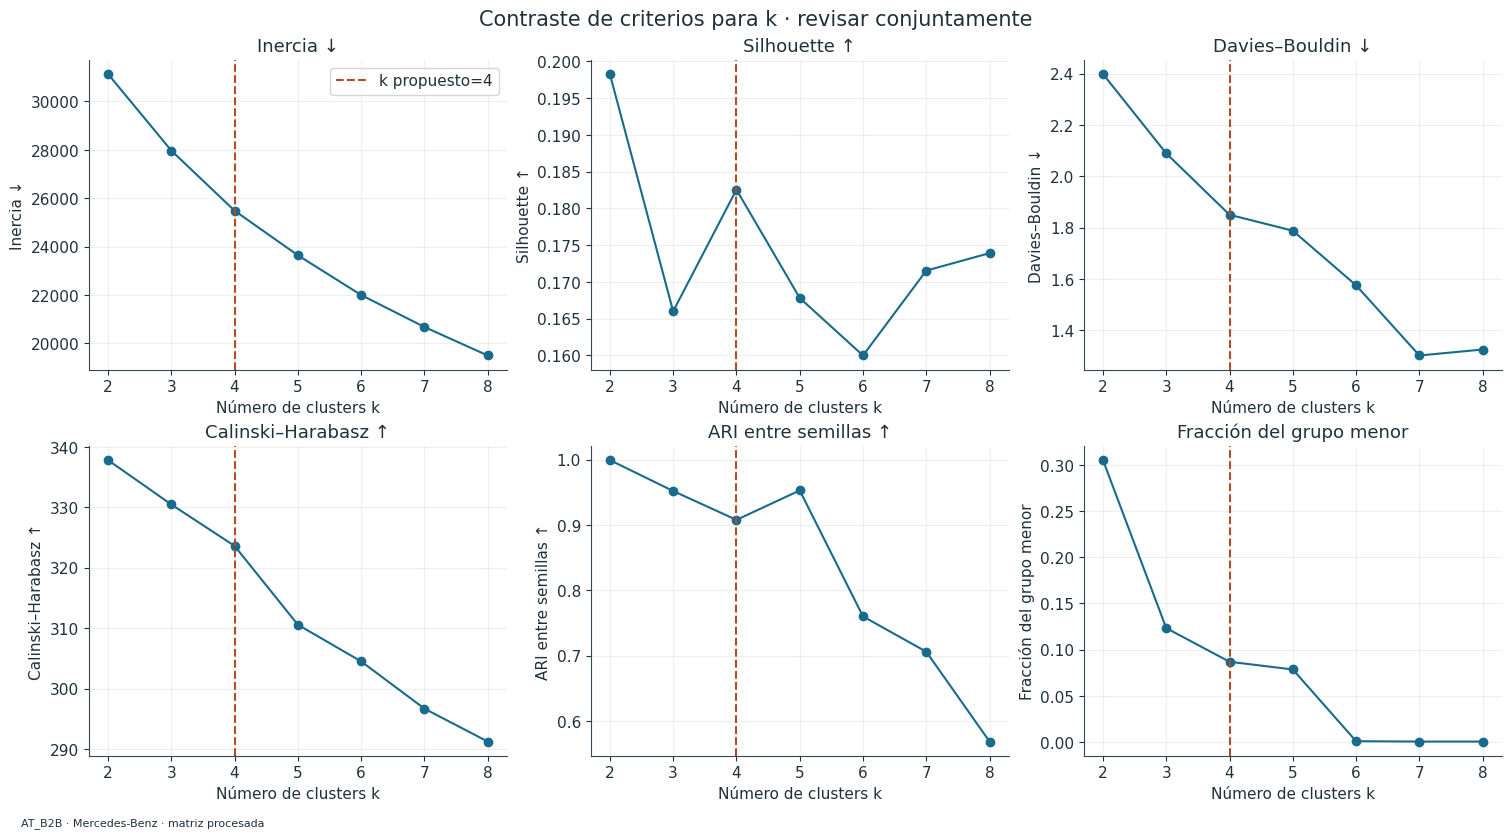

AT_B2C · selección de k


,k,Inercia ↓,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,ARI entre semillas ↑,Grupo mínimo,Seleccionado
0,2,1.364320e+06,0.1095,2.8231,11024.3829,0.9999,0.4163,False
1,3,1.275118e+06,0.1152,2.5249,9655.9770,0.9945,0.1447,False
2,4,1.195114e+06,0.1170,2.2944,9265.7268,0.9979,0.0870,False
3,5,1.125366e+06,0.1253,2.1426,9044.7540,0.9993,0.0844,True
4,6,1.071235e+06,0.1317,2.0100,8687.2232,0.9065,0.0380,False
5,7,1.025385e+06,0.1138,2.0233,8363.7060,0.9828,0.0299,False
6,8,9.840603e+05,0.1177,1.9433,8114.4385,0.8741,0.0269,False


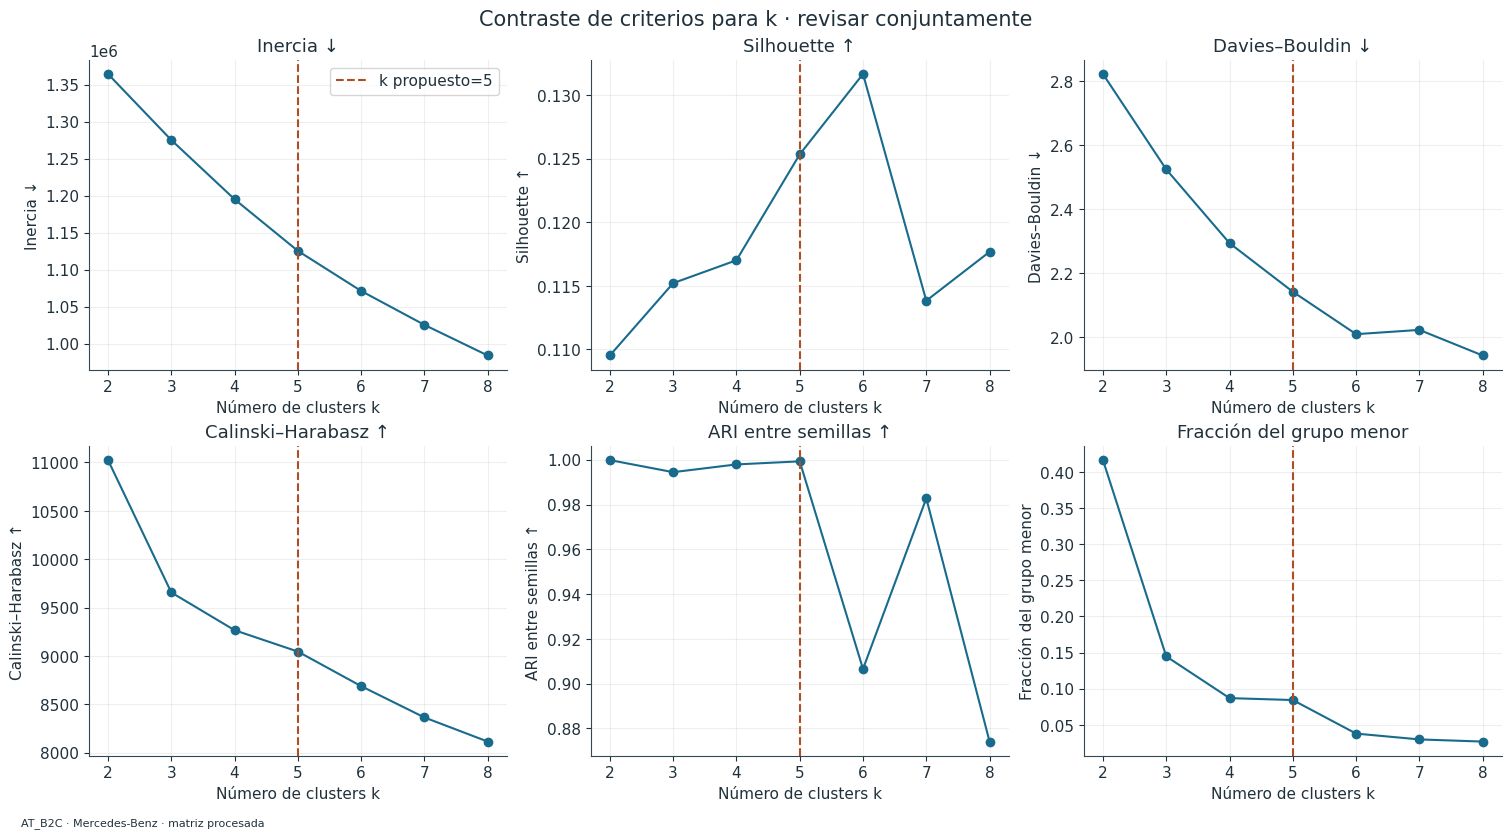

CH_B2B · selección de k


,k,Inercia ↓,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,ARI entre semillas ↑,Grupo mínimo,Seleccionado
0,2,37013.8011,0.4515,1.6036,402.5979,1.0000,0.0610,True
1,3,34065.5883,0.1097,2.3735,348.2921,0.9893,0.0580,False
2,4,31746.5211,0.1197,2.1975,322.0011,0.8581,0.0604,False
3,5,29777.4369,0.1320,1.9515,306.8803,0.9717,0.0320,False
4,6,28400.8607,0.1230,1.9449,286.3376,0.5054,0.0317,False
5,7,26682.6423,0.1304,1.8669,286.0050,0.6318,0.0263,False
6,8,25408.0822,0.1368,1.7702,278.7901,0.5071,0.0287,False


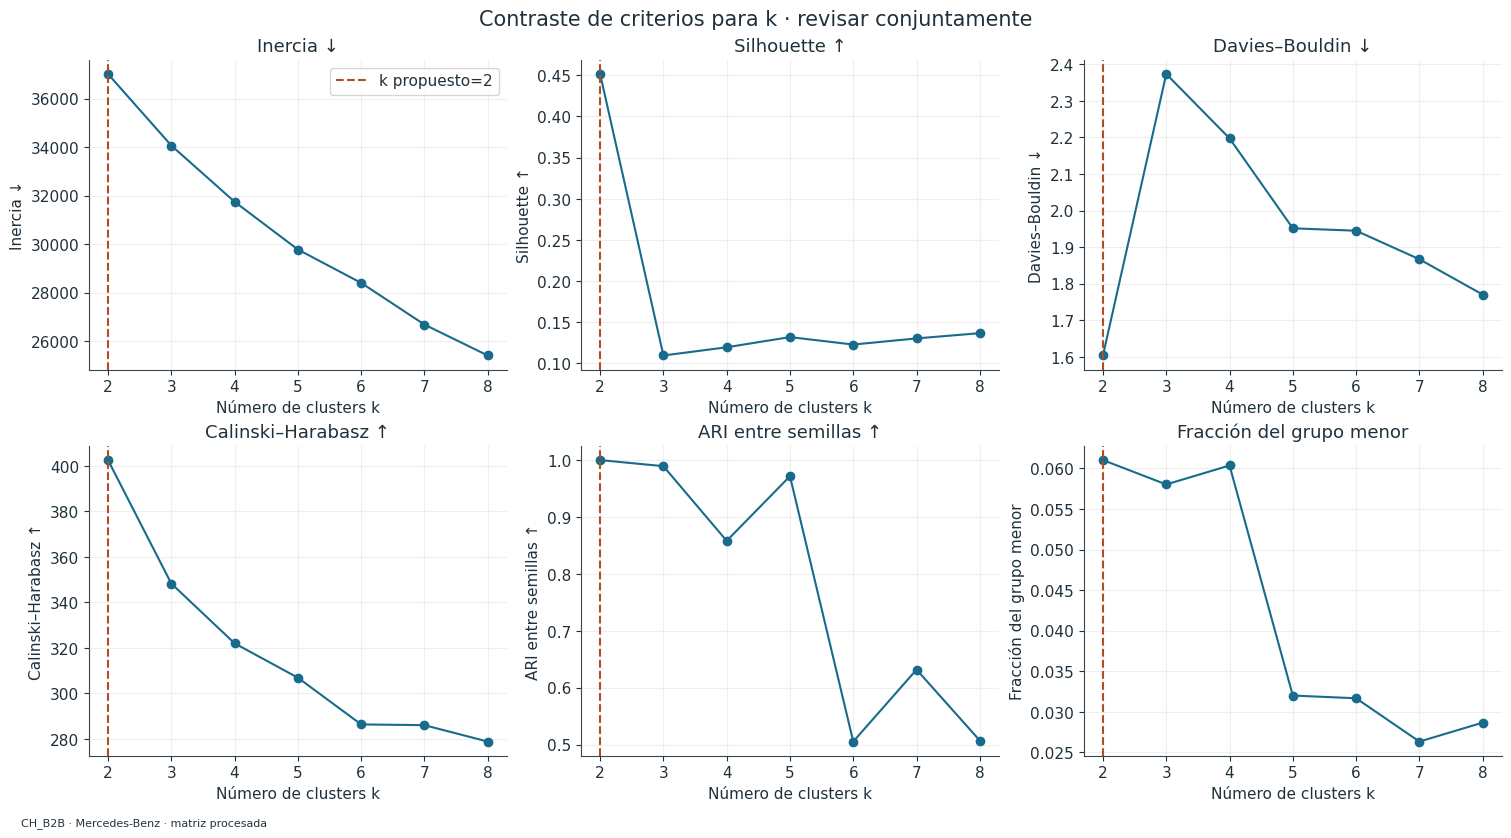

CH_B2C · selección de k


,k,Inercia ↓,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,ARI entre semillas ↑,Grupo mínimo,Seleccionado
0,2,2.404751e+06,0.1237,2.7902,20020.6419,0.9904,0.3965,False
1,3,2.244700e+06,0.0971,2.6667,17493.1923,0.7692,0.2772,False
2,4,2.103772e+06,0.1046,2.3262,16683.1538,0.9969,0.0460,False
3,5,1.994548e+06,0.1158,2.1817,15797.0460,0.4847,0.0449,False
4,6,1.894929e+06,0.1158,2.1333,15298.1555,0.9998,0.0444,False
5,7,1.812862e+06,0.1215,2.0302,14758.0771,0.9999,0.0433,True
6,8,1.732960e+06,0.1248,1.9125,14483.5971,0.9998,0.0432,False


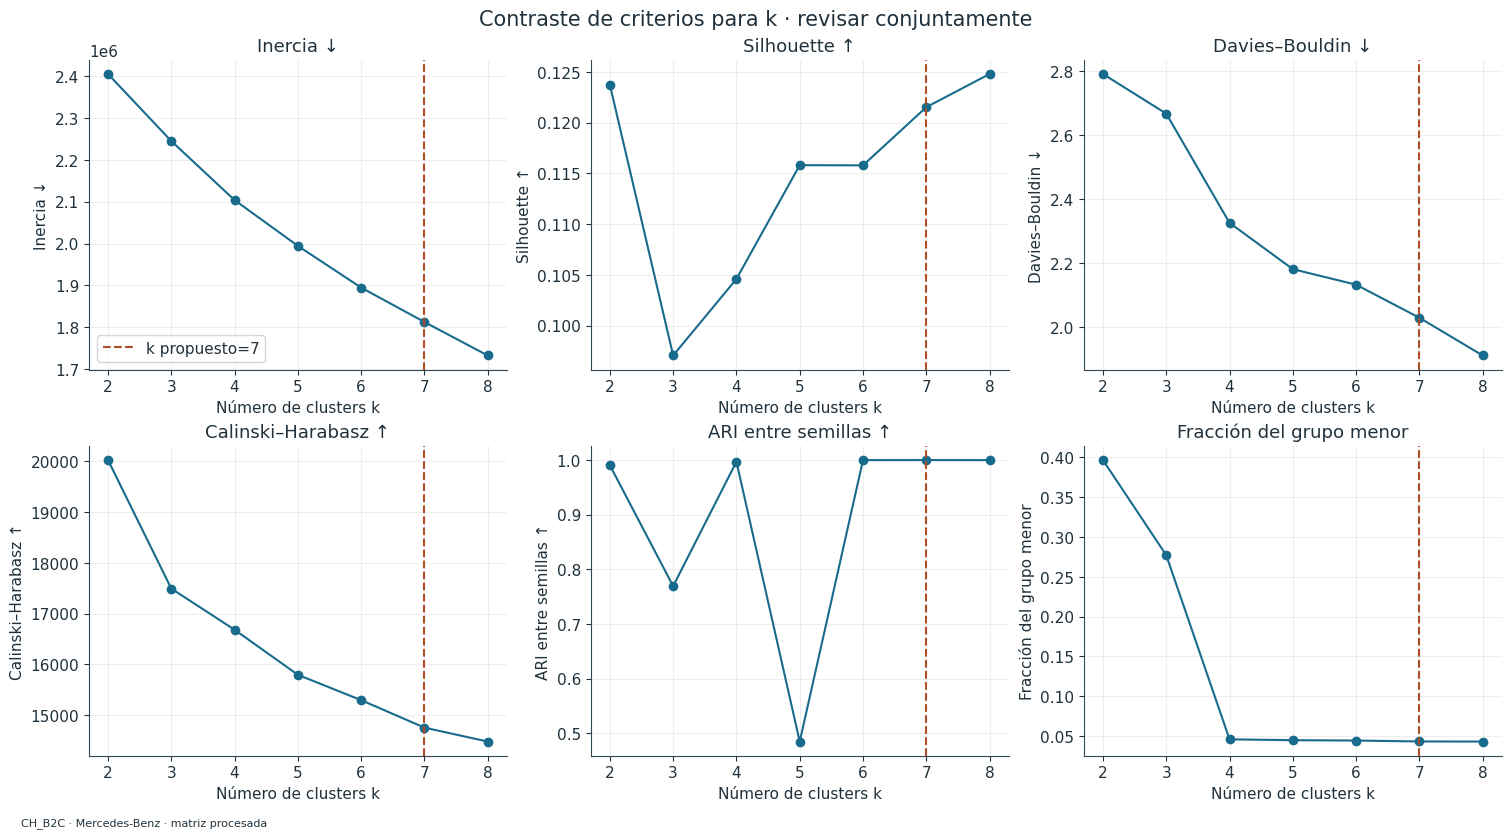

In [50]:
for segment, context in analyses.items():
    data = context["data"]
    search = search_kmeans(data,K_VALUES,random_state=SEED,n_init=N_INIT,
        seed_repeats=SEED_REPEATS,silhouette_sample_size=SILHOUETTE_SAMPLE_SIZE)
    k, evidence, reason = select_k(search.table)
    # Reutilizar el modelo ya entrenado para ese k: no repetir el ajuste final.
    context.update(model=search.models[k], labels=search.models[k].labels_.copy(), evidence=evidence, reason=reason)
    display_table(evidence[["k","inertia","silhouette","davies_bouldin","calinski_harabasz",
        "seed_ari_mean","min_cluster_fraction","selected"]],segment+" · selección de k")
    plot_k_search(evidence,k)
    show_figures(segment)


## Fronteras y Silhouette individual

La distancia al bisector de Voronoi mide cercanía a una frontera; no es probabilidad. Se normaliza por radio RMS, con alerta ≤0.15. El Silhouette individual estima a y b contra anclas uniformes para cada cliente y calcula distancias por bloques. Una estimación sin cobertura queda desconocida. La señal radial se conserva separada.


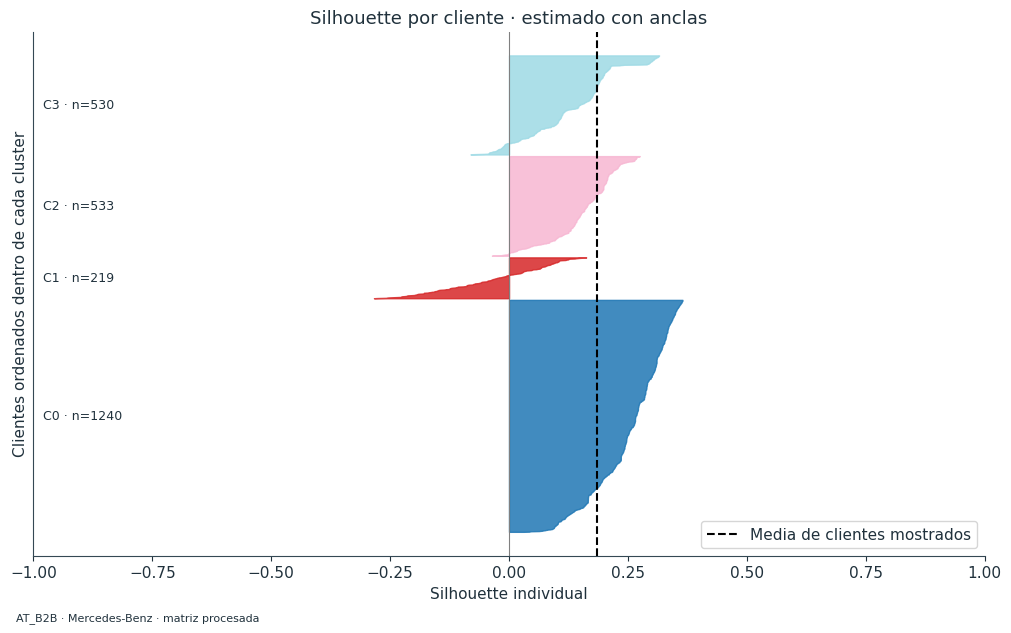

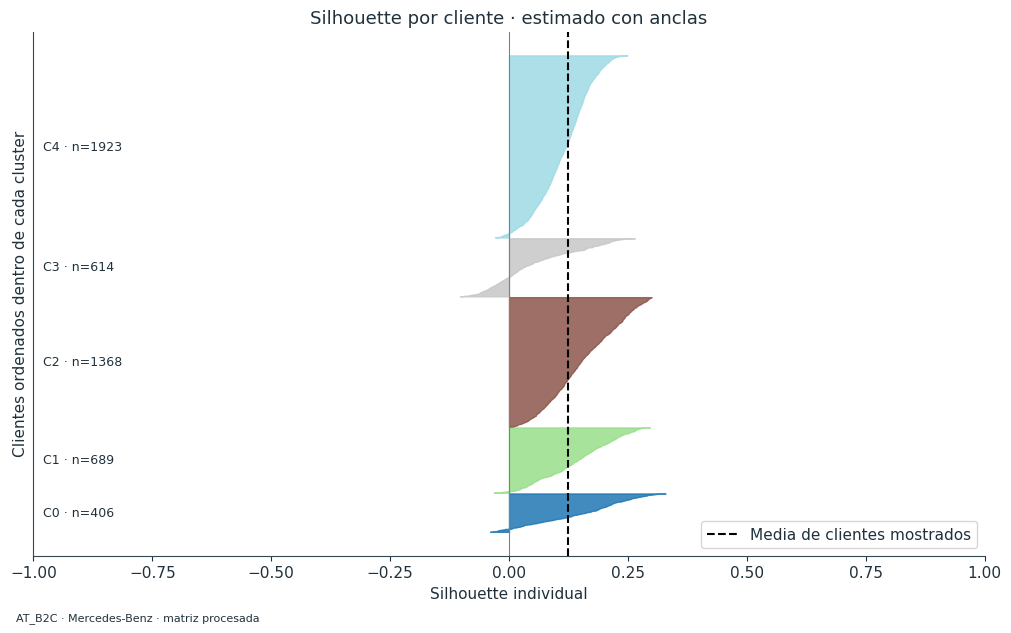

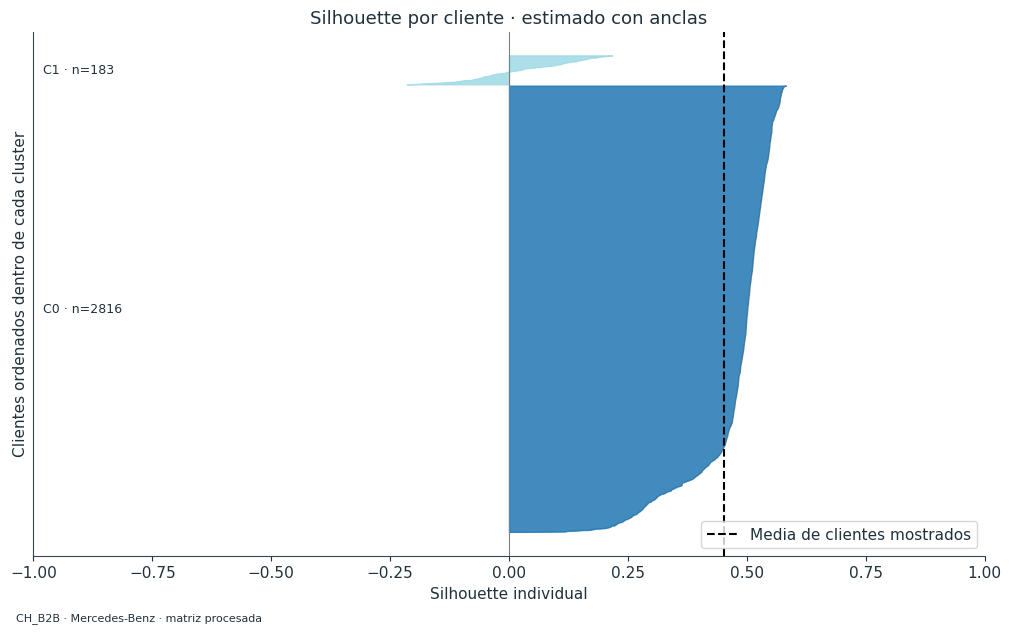

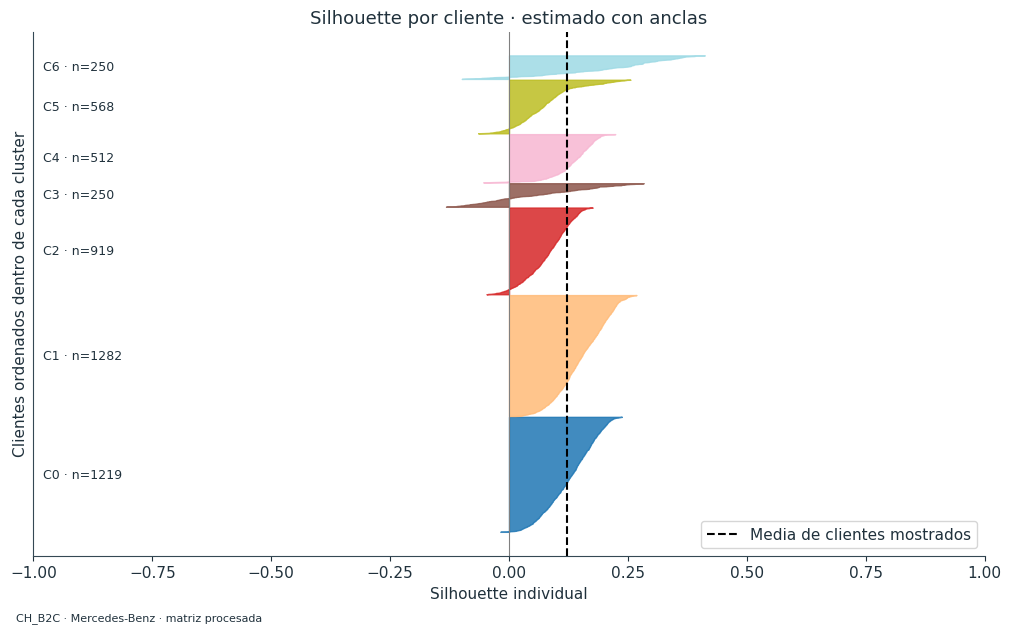

In [51]:
for segment, context in analyses.items():
    data, model, labels = context["data"],context["model"],context["labels"]
    clients = kmeans_boundaries(data,model,boundary_threshold=BOUNDARY_THRESHOLD,radial_quantile=.95)
    clients = clients.join(individual_silhouette(data.X,labels,reference_size=INDIVIDUAL_REFERENCE_SIZE,random_state=SEED))
    clients["low_silhouette"] = clients["silhouette"] <= .1
    context["clients"] = clients
    keep_table(segment,"diagnósticos por cliente",clients)
    plot_silhouette_clients(labels,clients["silhouette"],estimated=bool(clients["silhouette_estimated"].iloc[0]))
    show_figures(segment)


## Tamaños y conexiones entre segmentos

Los pares con alta dispersión relativa o con clientes cerca del bisector merecen revisión. Las asignaciones duras son disjuntas; no se interpreta el diagnóstico como volumen de una intersección.


AT_B2B · cohesión y tamaño


,Cluster,Clientes,Proporción,mean_radius,rms_radius,radius_q95,Fracción fronteriza
0,0,1240,0.4917,2.4367,2.5194,3.6026,0.0710
1,1,219,0.0868,4.8114,6.1583,9.3763,0.2831
2,2,533,0.2113,2.7461,2.9108,4.5273,0.1182
3,3,530,0.2102,2.8813,3.0066,4.3375,0.1377


AT_B2B · separación entre centroides


,cluster_a,cluster_b,centroid_distance,scatter_over_separation
0,0,1,4.7018,1.5415
1,0,2,2.9238,1.7726
2,0,3,2.7198,1.9553
3,1,2,4.4004,1.7175
4,1,3,4.9064,1.5679
5,2,3,3.3707,1.6695


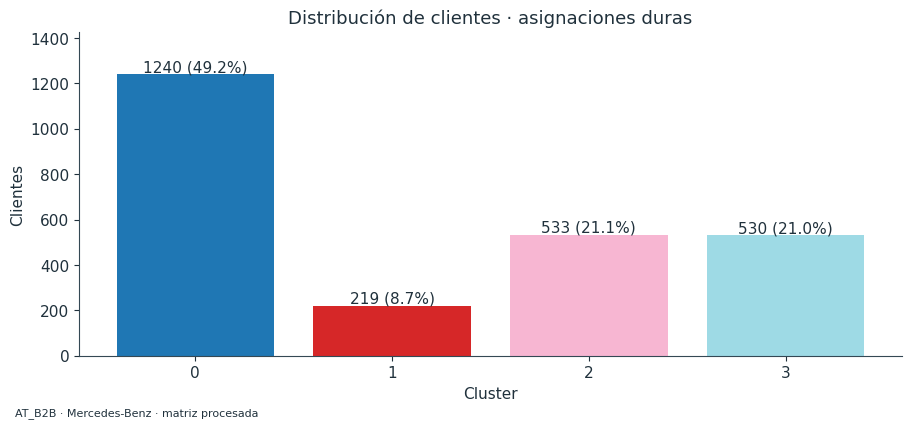

AT_B2C · cohesión y tamaño


,Cluster,Clientes,Proporción,mean_radius,rms_radius,radius_q95,Fracción fronteriza
0,0,9067,0.0844,3.2833,3.5665,5.2641,0.2092
1,1,14679,0.1366,2.8830,3.0587,4.4039,0.1578
2,2,29283,0.2725,2.7234,2.8869,4.2109,0.2340
3,3,13269,0.1235,3.4073,3.7156,5.4007,0.3502
4,4,41152,0.3830,2.9150,3.2901,4.7643,0.2051


AT_B2C · separación entre centroides


,cluster_a,cluster_b,centroid_distance,scatter_over_separation
0,0,1,4.1921,1.4710
1,0,2,3.4673,1.7324
2,0,3,4.4408,1.5066
3,0,4,3.8945,1.5915
4,1,2,2.9408,1.9065
5,1,3,3.7576,1.6740
6,1,4,2.8958,2.0022
7,2,3,3.3073,1.8537
8,2,4,2.3158,2.4347
9,3,4,2.9980,2.1089


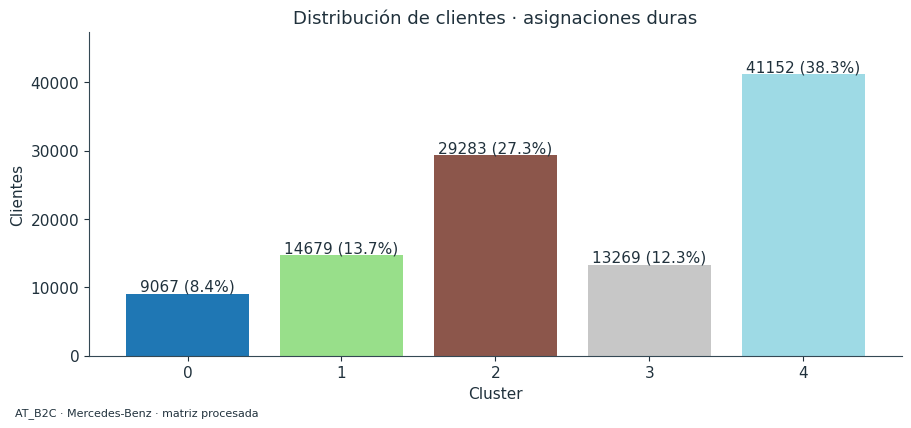

CH_B2B · cohesión y tamaño


,Cluster,Clientes,Proporción,mean_radius,rms_radius,radius_q95,Fracción fronteriza
0,0,2816,0.939,3.0601,3.2715,5.2422,0.0135
1,1,183,0.061,5.5663,6.1292,10.2200,0.1311


CH_B2B · separación entre centroides


,cluster_a,cluster_b,centroid_distance,scatter_over_separation
0,0,1,5.3792,1.6036


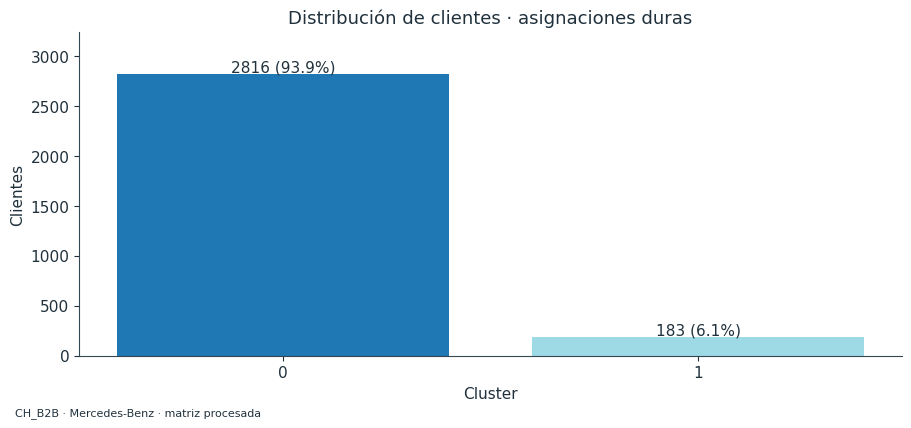

CH_B2C · cohesión y tamaño


,Cluster,Clientes,Proporción,mean_radius,rms_radius,radius_q95,Fracción fronteriza
0,0,44993,0.2370,2.6355,2.7753,4.0501,0.1820
1,1,49070,0.2584,2.5896,2.7254,4.0595,0.2389
2,2,34801,0.1833,2.8446,3.4302,4.6903,0.2707
3,3,9465,0.0498,3.3841,3.8212,6.2357,0.3956
4,4,19586,0.1031,2.9060,3.0360,4.3945,0.0728
5,5,23738,0.1250,3.1022,3.3910,4.8935,0.2971
6,6,8226,0.0433,3.3370,3.4980,5.0458,0.1349


CH_B2C · separación entre centroides


,cluster_a,cluster_b,centroid_distance,scatter_over_separation
0,0,1,2.2454,2.3270
1,0,2,2.9634,1.8493
2,0,3,4.3663,1.3786
3,0,4,3.2443,1.7081
4,0,5,3.3768,1.6992
5,0,6,4.4965,1.3283
6,1,2,2.2930,2.3699
7,1,3,3.9846,1.4992
8,1,4,2.9473,1.8646
9,1,5,2.9503,1.9292


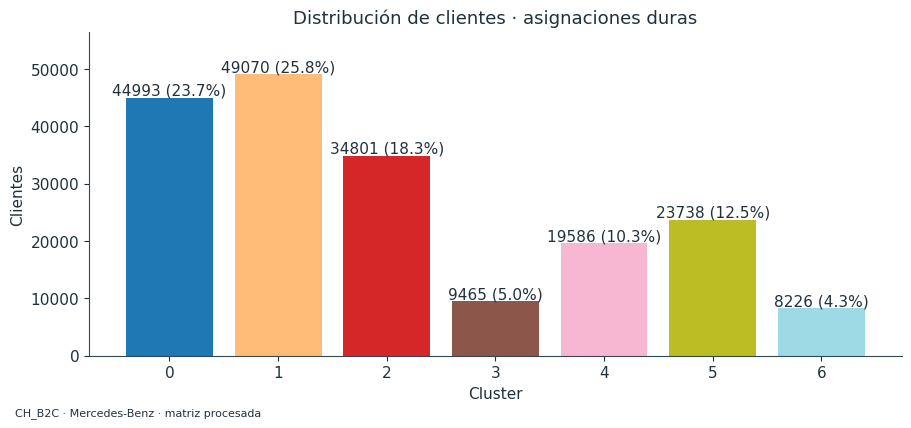

In [52]:
for segment, context in analyses.items():
    geometry,pairs = partition_geometry(context["data"].X,context["labels"])
    flags = context["clients"].groupby("cluster").agg(boundary_fraction=("near_boundary","mean"))
    display_table(geometry.merge(flags,left_on="cluster",right_index=True),segment+" · cohesión y tamaño")
    display_table(pairs,segment+" · separación entre centroides")
    plot_cluster_sizes(context["labels"])
    show_figures(segment)


## Preparar el experimento de hiperparámetros

Los barridos exploratorios comparten una muestra uniforme de hasta 20.000 filas, separada de la comparación principal. Mantienen k y la semilla de evaluación. El objetivo es comprobar sensibilidad, sin elegir automáticamente el mejor score.


In [53]:
for segment, context in analyses.items():
    data = context["data"]
    positions = evaluation_indices(data.n_samples,HYPERPARAMETER_MAX_SAMPLES,SEED)
    frame = pd.DataFrame(data.X[positions],columns=data.feature_names)
    frame.insert(0,"client_id",data.client_ids.iloc[positions].to_numpy())
    context["sweep_data"] = load_features(frame)
    runs = sweep_baselines(context["sweep_data"],[context["model"].n_clusters],
        seeds=(SEED,SEED+1),covariance_types=(),kmeans_n_init=(10,20),kmeans_init=("k-means++","random"))
    display_table(runs[["n_init","init","seed","silhouette","davies_bouldin","seed_ari_vs_first","status"]],
        f"{segment} · {len(positions):,} filas del barrido")
    keep_table(segment,"barrido K-Means",runs)


AT_B2B · 2,522 filas del barrido


,n_init,init,seed,Silhouette ↑,Davies–Bouldin ↓,seed_ari_vs_first,Estado
0,10,k-means++,42,0.1835,1.8460,NaN,ok
1,10,k-means++,43,0.1771,1.8745,0.9215,ok
2,10,random,42,0.1779,1.8740,NaN,ok
3,10,random,43,0.1835,1.8468,0.8958,ok
4,20,k-means++,42,0.1826,1.8502,NaN,ok
5,20,k-means++,43,0.1771,1.8745,0.9066,ok
6,20,random,42,0.1779,1.8740,NaN,ok
7,20,random,43,0.1770,1.8738,0.9771,ok


AT_B2C · 20,000 filas del barrido


,n_init,init,seed,Silhouette ↑,Davies–Bouldin ↓,seed_ari_vs_first,Estado
0,10,k-means++,42,0.1227,2.1343,NaN,ok
1,10,k-means++,43,0.1225,2.1347,0.9664,ok
2,10,random,42,0.1219,2.1348,NaN,ok
3,10,random,43,0.1250,2.1323,0.8418,ok
4,20,k-means++,42,0.1227,2.1343,NaN,ok
5,20,k-means++,43,0.1225,2.1345,0.9661,ok
6,20,random,42,0.1225,2.1347,NaN,ok
7,20,random,43,0.1225,2.1346,0.9995,ok


CH_B2B · 2,999 filas del barrido


,n_init,init,seed,Silhouette ↑,Davies–Bouldin ↓,seed_ari_vs_first,Estado
0,10,k-means++,42,0.4515,1.6036,NaN,ok
1,10,k-means++,43,0.4515,1.6036,1.0000,ok
2,10,random,42,0.4515,1.6036,NaN,ok
3,10,random,43,0.4030,1.8411,0.7631,ok
4,20,k-means++,42,0.4515,1.6036,NaN,ok
5,20,k-means++,43,0.4515,1.6036,1.0000,ok
6,20,random,42,0.4515,1.6036,NaN,ok
7,20,random,43,0.4515,1.6036,1.0000,ok


CH_B2C · 20,000 filas del barrido


,n_init,init,seed,Silhouette ↑,Davies–Bouldin ↓,seed_ari_vs_first,Estado
0,10,k-means++,42,0.1214,2.0348,NaN,ok
1,10,k-means++,43,0.1215,2.0348,0.9935,ok
2,10,random,42,0.1218,2.0349,NaN,ok
3,10,random,43,0.1215,2.0348,0.9898,ok
4,20,k-means++,42,0.1215,2.0346,NaN,ok
5,20,k-means++,43,0.1216,2.0350,0.9652,ok
6,20,random,42,0.1240,2.0267,NaN,ok
7,20,random,43,0.1215,2.0348,0.9349,ok


## Decisión y referencia para las siguientes entregas

Se conserva el ajuste ya evaluado para el k propuesto y su trazabilidad por cliente. Los metadatos descriptivos se incorporan después del ajuste, en 04; no intervienen en distancias ni selección de k.


In [54]:
for segment, context in analyses.items():
    context["findings"] = [context["reason"],
        f"En la entrada, {context['variance_driver']} concentra {context['variance_share']:.1%} de la varianza; se utiliza la representación {SCALING_POLICY} para evitar dominancia por escala.",
        f"{int(context['clients']['near_boundary'].sum())} clientes próximos a fronteras; {int(context['clients']['low_silhouette'].sum())} con Silhouette bajo.",
        "La interpretación posterior cruzará atributos de negocio por clave, manteniendo intacta la geometría del modelo."]
    record_reference(study,segment,context["data"],context["model"],context["clients"],context["evidence"])
    study["segments"][segment]["representation"] = context["representation"]
    display(ReportPanel(segment+" · decisión de segmentación",{"k":context["model"].n_clusters},context["findings"],"Referencia para las siguientes entregas"))


# AT_B2B · decisión de segmentación

Referencia para las siguientes entregas

| Indicador | Resultado |
| --- | --- |
| k | 4 |

- Propuesta heurística multicriterio; revisar codo, métricas, tamaños y estabilidad. k=4; Silhouette=0.183, DB=1.850, CH=323.6, grupo mínimo=8.7%.
- En la entrada, population concentra 43.9% de la varianza; se utiliza la representación standardize para evitar dominancia por escala.
- 286 clientes próximos a fronteras; 492 con Silhouette bajo.
- La interpretación posterior cruzará atributos de negocio por clave, manteniendo intacta la geometría del modelo.

# AT_B2C · decisión de segmentación

Referencia para las siguientes entregas

| Indicador | Resultado |
| --- | --- |
| k | 5 |

- Propuesta heurística multicriterio; revisar codo, métricas, tamaños y estabilidad. k=5; Silhouette=0.125, DB=2.143, CH=9044.8, grupo mínimo=8.4%.
- En la entrada, speed_median concentra 81.3% de la varianza; se utiliza la representación standardize para evitar dominancia por escala.
- 24153 clientes próximos a fronteras; 39114 con Silhouette bajo.
- La interpretación posterior cruzará atributos de negocio por clave, manteniendo intacta la geometría del modelo.

# CH_B2B · decisión de segmentación

Referencia para las siguientes entregas

| Indicador | Resultado |
| --- | --- |
| k | 2 |

- Propuesta heurística multicriterio; revisar codo, métricas, tamaños y estabilidad. k=2; Silhouette=0.452, DB=1.604, CH=402.6, grupo mínimo=6.1%.
- En la entrada, currently_connected_vehicles concentra 19.3% de la varianza; se utiliza la representación standardize para evitar dominancia por escala.
- 62 clientes próximos a fronteras; 127 con Silhouette bajo.
- La interpretación posterior cruzará atributos de negocio por clave, manteniendo intacta la geometría del modelo.

# CH_B2C · decisión de segmentación

Referencia para las siguientes entregas

| Indicador | Resultado |
| --- | --- |
| k | 7 |

- Propuesta heurística multicriterio; revisar codo, métricas, tamaños y estabilidad. k=7; Silhouette=0.122, DB=2.030, CH=14758.1, grupo mínimo=4.3%.
- En la entrada, speed_median concentra 84.1% de la varianza; se utiliza la representación standardize para evitar dominancia por escala.
- 42664 clientes próximos a fronteras; 72566 con Silhouette bajo.
- La interpretación posterior cruzará atributos de negocio por clave, manteniendo intacta la geometría del modelo.

## Alcance y siguiente decisión

Se conserva K-Means sobre X de modelado como referencia común. El valor de k es una propuesta contrastada, no un número verdadero de segmentos. La interpretación comercial y las hipótesis de campañas comienzan en 04; la decisión de uso se condiciona a 05–07. [Estandarización de variables](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).


In [55]:
# El paquete conserva los resultados previos; cada cuaderno añade solo su aportación.
save_study(study, REFERENCE_FILE)
RUN_REPORT = dict(step="03", source="real", versions=VERSIONS,
    segments=[dict(segment_id=segment, clients=context["data"].n_samples,
                   features=context["data"].n_features, k=int(context["model"].n_clusters),
                   scaling_policy=context["representation"]["policy"])
              for segment, context in analyses.items()],
    findings={segment:context["findings"] for segment,context in analyses.items()},
    elapsed_seconds=round(perf_counter()-STARTED,3))
print("Resultados actualizados en " + REFERENCE_FILE + ". Para continuar en otra sesión, conservar este paquete junto a los CSV.")


Resultados actualizados en segmentacion_ml.zip. Para continuar en otra sesión, conservar este paquete junto a los CSV.
